# ¿Dónde vive el miedo? 120 canciones, 1980–2026

**Cuaderno en español · lectura ciega por pares + embeddings locales · corte: 11 de octubre de 2026**

La pregunta: cuando una canción popular habla de miedo, **¿de qué tiene miedo, quién lo siente, cómo responde y qué protege?** ¿Y cómo cambia eso entre 1980 y 2026?

El cuaderno combina dos mediciones independientes sobre las mismas 120 letras (12 en inglés y 12 en español por período):

1. **Lectura ciega por pares.** Seis procesos lectores (el mismo asistente, con protocolo fijo) leen cada letra sin artista, título ni año. Cada canción recibe dos lecturas: si hay miedo, dónde está la amenaza, quién teme, cómo responde la voz, el estado de cada bloque y qué está en juego.
2. **Geometría de embeddings.** `multilingual-e5-large-instruct`, local, con una instrucción orientada al miedo, sin la señal de idioma, proyectado sobre ejes construidos con frases ancla bilingües. Los ejes no ven las lecturas.

### Hallazgos

| | Qué cambia | Evidencia |
|---|---|---|
| 1 | **Dónde.** La amenaza se muda de la calle, el Estado y el monstruo a la pareja y, después, a la propia mente. | Lectores: amenaza colectiva −12,9 pts/década (p = 0,01); interior +8,2 (p = 0,02). Embeddings, sin etiquetas: eje afuera→adentro +0,23 DE/década (p = 0,01), estable en cuatro encoders. |
| 2 | **Quién.** El miedo pasa de narrarse (tú, ellos) a confesarse (yo) y, en los 2010, a compartirse (nosotros). | Teme quien canta: 40 % → 100 % (2010–19); +12,7 pts/década (p = 0,005). |
| 3 | **Cómo se mueve la canción.** Menos miedo que crece, más miedo que se atraviesa. El bucle persiste. | Escalada 33 % → 6–10 %; giro a la agencia 3 % → 37–42 %; bucle ~30 % en todas las décadas. |
| 4 | **Qué protege.** De estar a salvo a la dignidad y, al final, a sanar. El vínculo amoroso no se mueve. | «Estar a salvo» 43 % → 0; «dignidad, libertad, voz» 71 % en 2010–19; «sanar» aparece en 2020–26 (32 %). |
| 5 | **Lección técnica.** Un embedding ve primero el idioma; el clustering libre no encuentra el lugar de la amenaza; una pregunta explícita sí. | 100 % de vecinos del mismo idioma sin corregir; kNN por debajo de la línea base; eje anclado AUC 0,89. |

Límites que acompañan cada número: muestra intencional (excluir las canciones elegidas *por* miedo debilita las tendencias), 6,5–13,5 canciones con miedo por período, lectores del mismo modelo y solo texto (sin audio).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

pd.set_option('future.infer_string', False)
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.width', 160)
candidates = [Path.cwd(), *Path.cwd().parents]
STUDY = next(d for p in candidates for d in [p / 'research/fear-lyrics', p] if (d / 'fear_story.py').exists())
ROOT = STUDY.parents[1] if (STUDY.parents[1] / 'static').exists() else STUDY
RES = STUDY / 'results' / 'story-v3'
FIG = ROOT / 'static' / 'research' / 'fear-lyrics' / 'story'
PLAB = {1980: '1980–89', 1990: '1990–99', 2000: '2000–09', 2010: '2010–19', 2020: '2020–26'}

def fig(name, width=1100):
    display(Image(filename=str(FIG / f'{name}.png'), width=width))

def pct(df, cols):
    return df.style.format({c: '{:.0%}' for c in cols})

table = pd.read_csv(RES / 'song_table.csv', index_col=0)
readings = pd.read_csv(RES / 'readings_public.csv')
trends = pd.read_csv(RES / 'trends.csv')
means = pd.read_csv(RES / 'period_means.csv')
fear = table[table.fear_weight > 0]
print(f'{len(table)} canciones · {len(readings)} lecturas · {len(fear)} con miedo explícito o implícito')

120 canciones · 240 lecturas · 56 con miedo explícito o implícito


## 1. El corpus y la selección

Cinco períodos por año de primera edición de la grabación; 12 canciones en inglés y 12 en español en cada uno; 2020–26 es parcial. La selección es **intencional**: el analista eligió candidatas asociadas al miedo, casos ambiguos y controles antes de ver resultados. Por eso el cuaderno compara **la composición dentro de las canciones con miedo**, no cuántas canciones con miedo hay por década: esa cifra depende de quién eligió la lista.

In [2]:
display(Markdown('**Etiqueta de selección del analista frente a la lectura ciega** (`agreed`: ambas lecturas ven miedo; `split`: solo una)'))
display(pd.crosstab(table.selection_label, table.fear_status, margins=True))
display(Markdown('**Peso de canciones con miedo por período e idioma** (1 = ambas lecturas; 0,5 = una)'))
display(fear.groupby(['period', 'language']).fear_weight.sum().unstack().rename(index=PLAB))

**Etiqueta de selección del analista frente a la lectura ciega** (`agreed`: ambas lecturas ven miedo; `split`: solo una)

fear_status,absent,agreed,split,All
selection_label,,,,
ambiguous,36,24,6,66
control,27,2,0,29
fear,1,24,0,25
All,64,50,6,120


**Peso de canciones con miedo por período e idioma** (1 = ambas lecturas; 0,5 = una)

language,en,es
period,,
1980–89,7.5,6.0
1990–99,6.5,2.0
2000–09,9.0,3.5
2010–19,8.5,3.5
2020–26,2.5,4.0


**Lectura.** De las 25 canciones elegidas como «miedo», 24 lo tienen según los lectores; 30 de 66 ambiguas y 2 de 29 controles también. Así, 32 de las 56 canciones con miedo no fueron elegidas por eso: la sección 9 repite los análisis solo con ellas.

## 2. La lectura ciega y su acuerdo

Protocolo: `story-reading-protocol.md`. Los bloques llegan en orden, con repeticiones marcadas; las salidas públicas solo contienen categorías, IDs y paráfrasis breves en español. El acuerdo es alto, pero ambos lectores son el mismo modelo: un κ alto mide consistencia del procedimiento, no independencia humana.

In [3]:
agreement = pd.read_csv(RES / 'reader_agreement.csv')
display(agreement.style.format({'agreement': '{:.0%}', 'kappa': '{:.2f}'}))

,field,songs,agreement,kappa
0,miedo presente (explícito/implícito),120,95%,0.90
1,fear_reference,120,89%,0.84
2,threat_locus,50,94%,0.92
3,response,50,86%,0.83
4,arc_shape,50,82%,0.76
5,who_fears,50,94%,0.90


## 3. Dónde está la amenaza

Seis lugares, del afuera al adentro: sociedad/Estado/calle, monstruo o presagio, otra persona, perder un vínculo, tiempo/futuro, la propia mente.

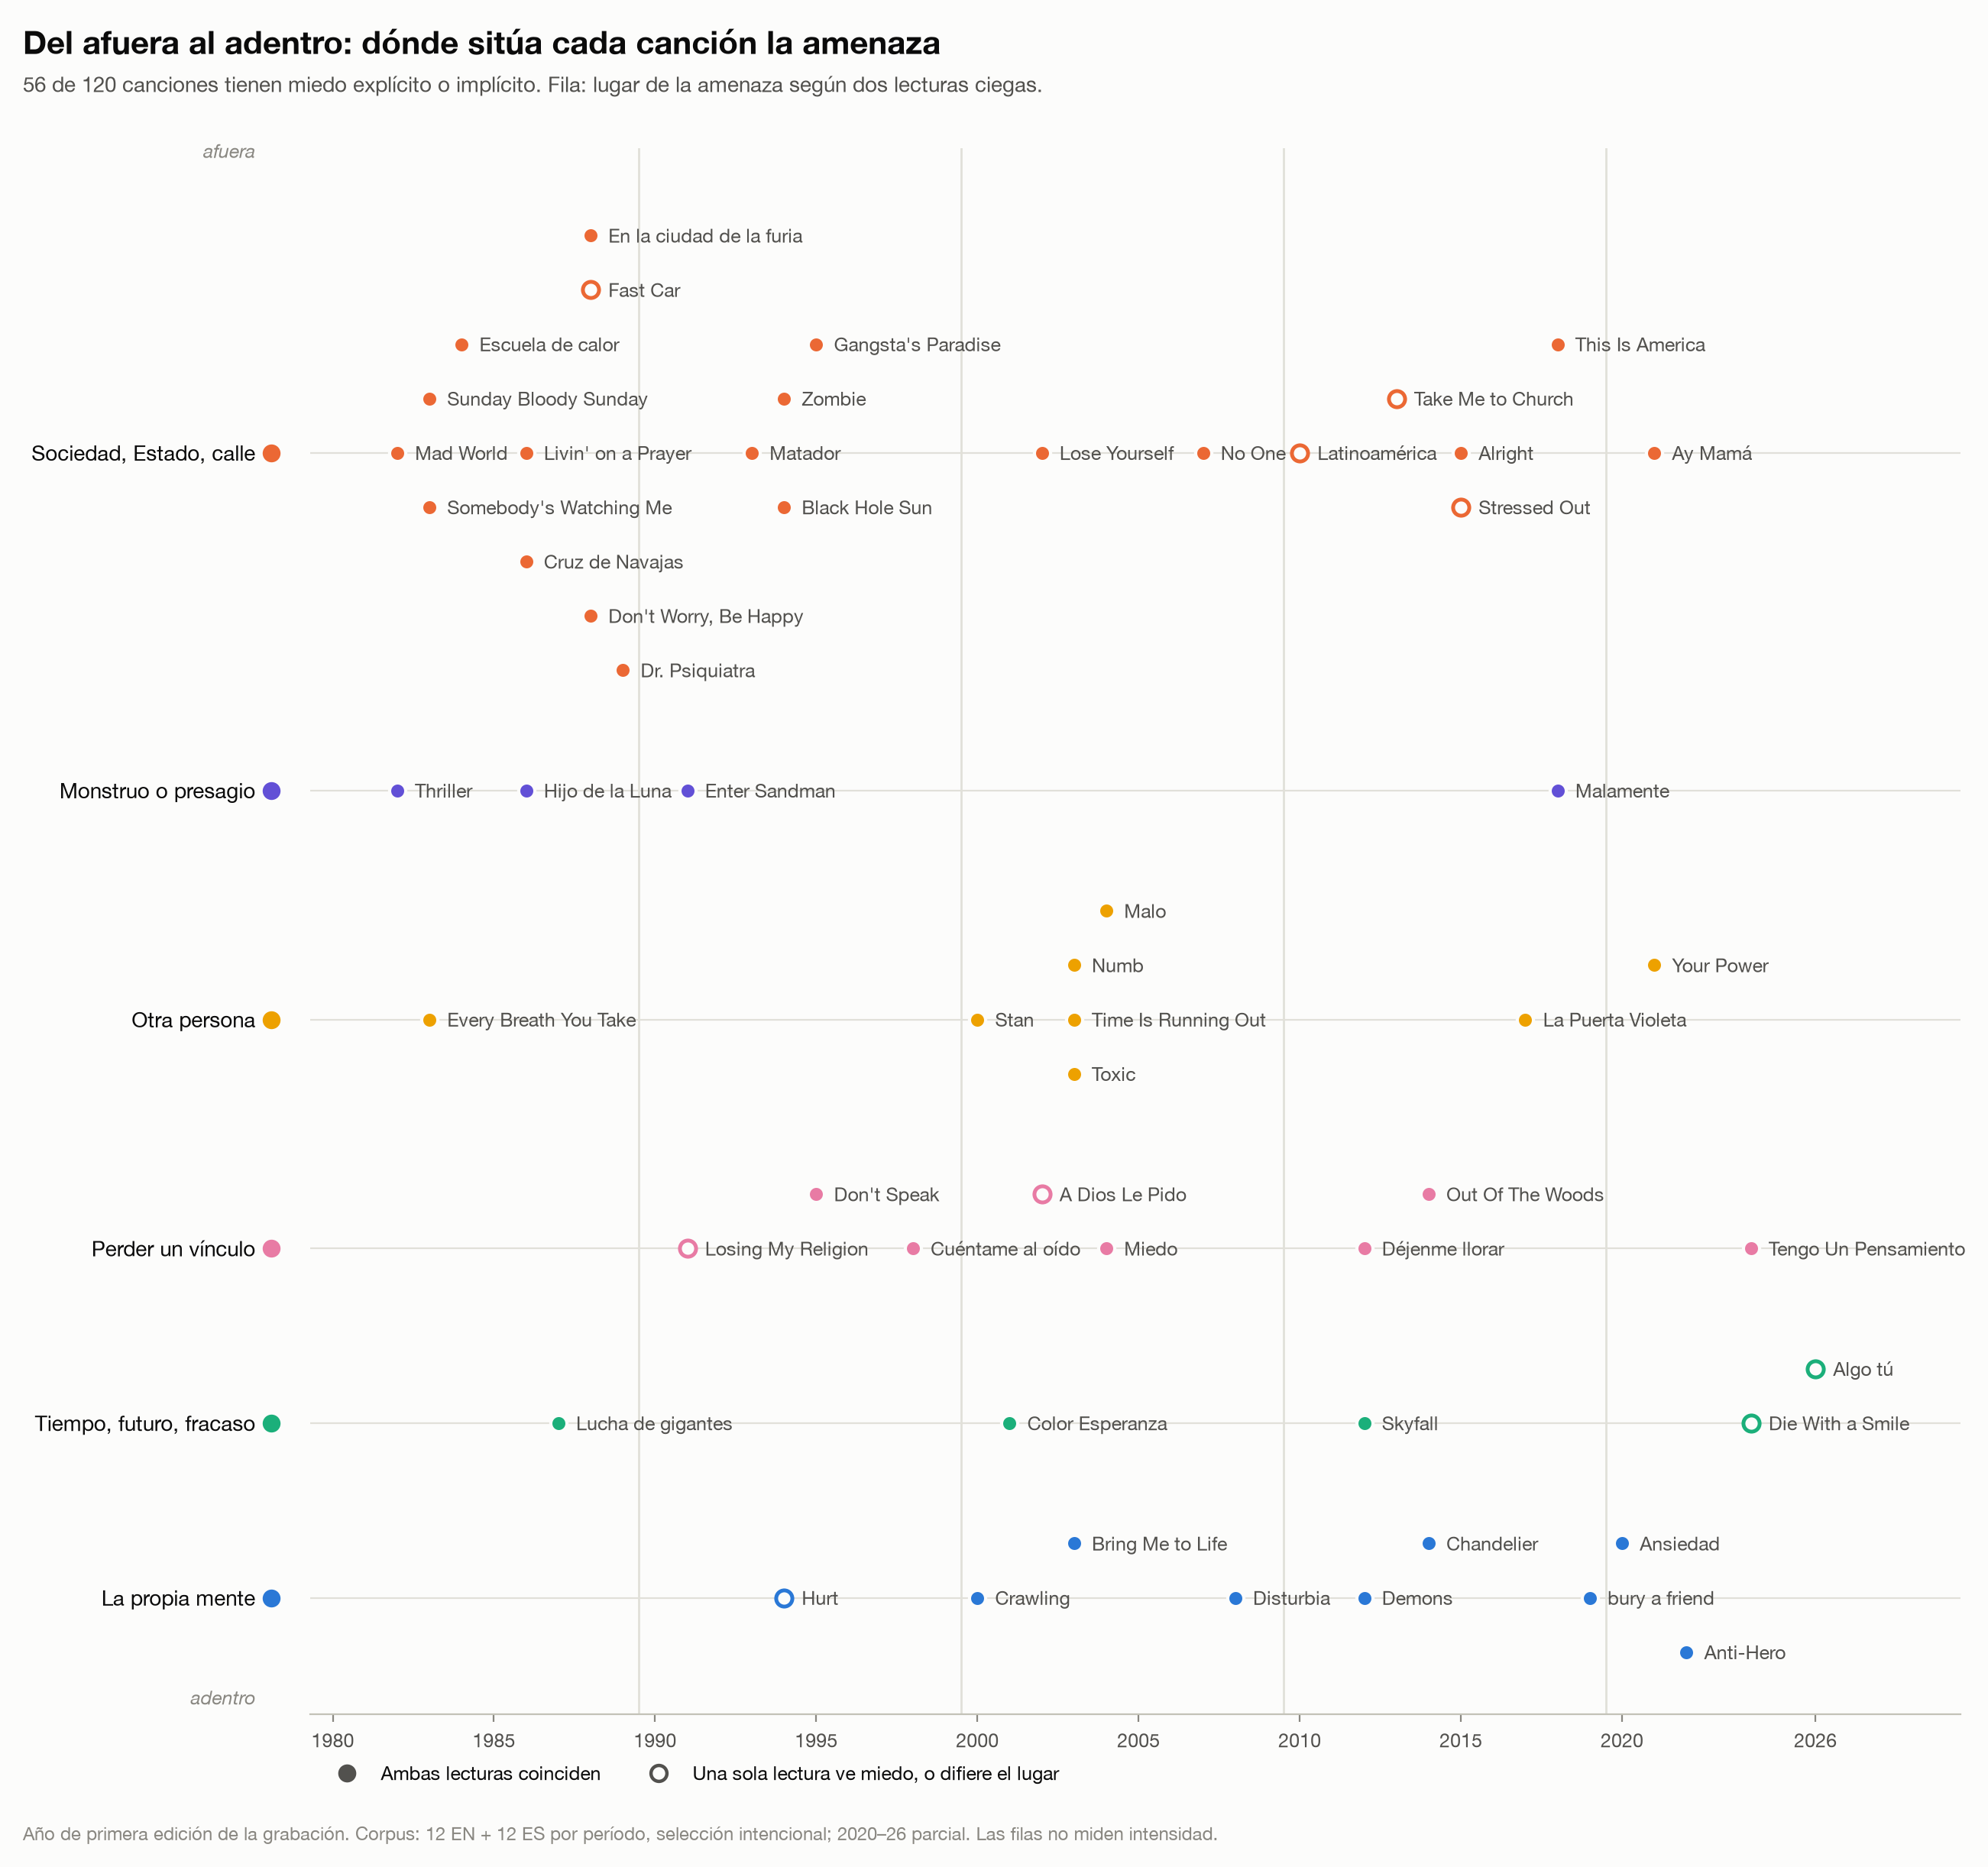

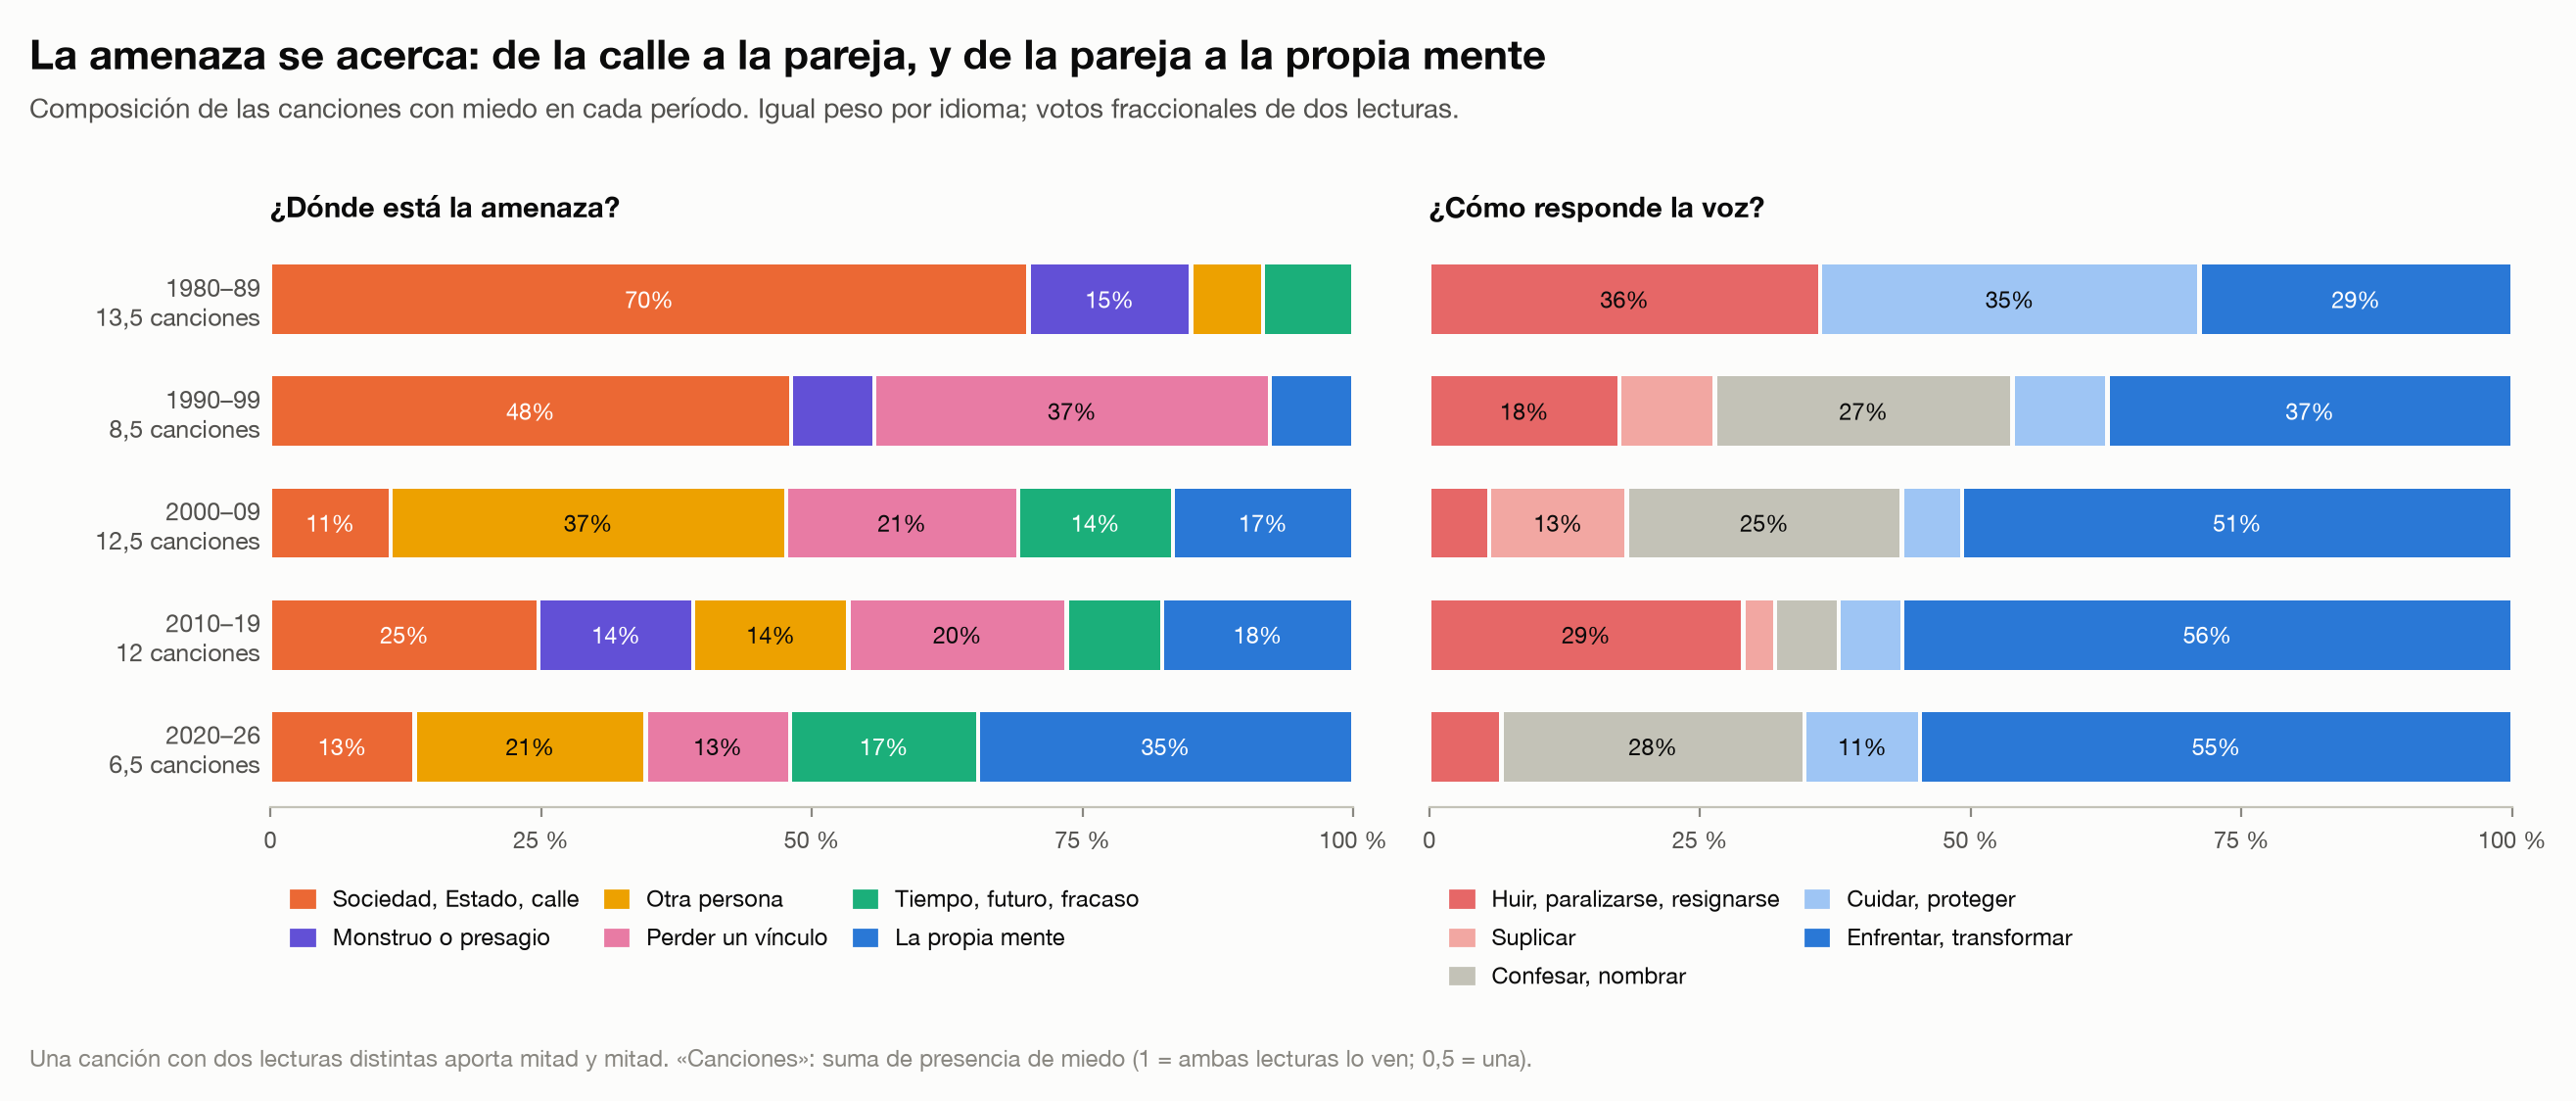

In [4]:
fig('fear-locus-timeline')
fig('fear-locus-periods')

In [5]:
cols = ['threat_locus:external_collective', 'threat_locus:external_person', 'threat_locus:relational_loss', 'threat_locus:internal_self']
view = means[(means.column.isin(cols)) & (means.language == 'both')].pivot(index='column', columns='period', values='mean')
view.columns = [PLAB[c] for c in view.columns]
display(Markdown('**Proporción por período** (igual peso por idioma)'))
display(view.style.format('{:.0%}'))
display(Markdown('**Tendencia por década** (WLS con efectos de idioma; p por permutación de años dentro de idioma)'))
display(trends[trends.measure.str.startswith('lectura: amenaza') | trends.measure.str.startswith('lectura: pérdida')]
        [['measure', 'slope_per_decade', 'p_two_sided', 'songs']].style.format({'slope_per_decade': '{:+.1%}', 'p_two_sided': '{:.3f}'}))

**Proporción por período** (igual peso por idioma)

,1980–89,1990–99,2000–09,2010–19,2020–26
column,,,,,
threat_locus:external_collective,70%,48%,11%,25%,12%
threat_locus:external_person,7%,0%,37%,14%,20%
threat_locus:internal_self,0%,8%,17%,18%,32%
threat_locus:relational_loss,0%,37%,21%,20%,12%


**Tendencia por década** (WLS con efectos de idioma; p por permutación de años dentro de idioma)

,measure,slope_per_decade,p_two_sided,songs
0,lectura: amenaza interior (internal_self),+8.2%,0.023,56
1,lectura: amenaza colectiva,-12.9%,0.010,56
2,lectura: amenaza de otra persona,+2.0%,0.595,56
4,lectura: pérdida de un vínculo,+2.7%,0.443,56


**Lectura.** En los ochenta, siete de cada diez canciones con miedo ponen la amenaza afuera: la vigilancia (*Somebody's Watching Me*), la ciudad (*En la ciudad de la furia*), la violencia sectaria (*Sunday Bloody Sunday*), la pobreza (*Livin' on a Prayer*, *Fast Car*) o el monstruo (*Thriller*). En los 2000 domina otra persona, casi siempre la pareja (*Toxic*, *Time Is Running Out*, *Malo*), y aparece la mente como amenaza (*Crawling*, *Bring Me to Life*, *Disturbia*). En 2020–26 la propia mente es el lugar más frecuente (*Ansiedad*, *Anti-Hero*).

La línea no es recta: en 2010–19 la calle vuelve (*Alright*, *This Is America*, *Latinoamérica*), ahora con una voz que enfrenta. Y los idiomas no recorren el mismo camino:

In [6]:
for col, name in [('threat_locus:internal_self', 'La propia mente'), ('threat_locus:external_person', 'Otra persona'),
                  ('threat_locus:relational_loss', 'Perder un vínculo')]:
    v = means[(means.column == col) & (means.language.isin(['en', 'es']))].pivot(index='language', columns='period', values='mean')
    n = means[(means.column == col) & (means.language.isin(['en', 'es']))].pivot(index='language', columns='period', values='songs')
    v.columns = [PLAB[c] for c in v.columns]
    display(Markdown(f'**{name}**, por idioma (canciones con miedo por celda: {", ".join(f"{x:g}" for x in n.values.ravel())})'))
    display(v.style.format('{:.0%}'))

**La propia mente**, por idioma (canciones con miedo por celda: 7.5, 6.5, 9, 8.5, 2.5, 6, 2, 3.5, 3.5, 4)

,1980–89,1990–99,2000–09,2010–19,2020–26
language,,,,,
en,0%,15%,33%,35%,40%
es,0%,0%,0%,0%,25%


**Otra persona**, por idioma (canciones con miedo por celda: 7.5, 6.5, 9, 8.5, 2.5, 6, 2, 3.5, 3.5, 4)

,1980–89,1990–99,2000–09,2010–19,2020–26
language,,,,,
en,13%,0%,44%,0%,40%
es,0%,0%,29%,29%,0%


**Perder un vínculo**, por idioma (canciones con miedo por celda: 7.5, 6.5, 9, 8.5, 2.5, 6, 2, 3.5, 3.5, 4)

,1980–89,1990–99,2000–09,2010–19,2020–26
language,,,,,
en,0%,23%,0%,12%,0%
es,0%,50%,43%,29%,25%


**Lectura.** En inglés, la mente aparece en los noventa y ocupa un tercio desde 2000 (grunge, nu-metal, pop confesional). En español no aparece hasta 2020 (*Ansiedad*); antes, el miedo íntimo pasa por la casa y la pareja (*Malo*, *La Puerta Violeta*) y por la pérdida (*A Dios Le Pido*, *Miedo*). Con 2–4 canciones por celda en español, esto es una observación de casos, no una estimación.

## 4. Quién tiene miedo

In [7]:
who = means[(means.column == 'first_person') & (means.language == 'both')][['period', 'mean', 'lo90', 'hi90', 'songs']]
who['period'] = who.period.map(PLAB)
display(Markdown('**Teme quien canta (yo o nosotros)**, con intervalo bootstrap del 90 %'))
display(who.style.format({'mean': '{:.0%}', 'lo90': '{:.0%}', 'hi90': '{:.0%}'}))
r = readings[readings.fear_reference.isin(['explicit', 'implied'])].assign(period=lambda d: d.year.map(lambda y: PLAB[min(y // 10 * 10, 2020)]))
display(pd.crosstab(r.period, r.who_fears, normalize='index').style.format('{:.0%}'))
display(trends[trends.measure.str.startswith('voz')][['measure', 'slope_per_decade', 'p_two_sided']].style.format({'slope_per_decade': '{:+.1%}', 'p_two_sided': '{:.3f}'}))

**Teme quien canta (yo o nosotros)**, con intervalo bootstrap del 90 %

,period,mean,lo90,hi90,songs
240,1980–89,40%,18%,62%,13.500000
241,1990–99,67%,36%,100%,8.500000
242,2000–09,77%,54%,97%,12.500000
243,2010–19,100%,100%,100%,12.000000
244,2020–26,68%,38%,100%,6.500000


who_fears,addressee,nobody,speaker,speaker_collective,third_party
period,,,,,
1980–89,30%,4%,33%,7%,26%
1990–99,24%,0%,65%,12%,0%
2000–09,12%,0%,80%,0%,8%
2010–19,0%,0%,58%,42%,0%
2020–26,0%,0%,69%,0%,31%


,measure,slope_per_decade,p_two_sided
16,voz: teme quien canta (yo o nosotros),+12.7%,0.005
17,voz: teme quien canta (yo),+8.9%,0.077


**Lectura.** En los ochenta, el miedo suele pertenecer a otro: el «tú» al que se dirige *Thriller*, los personajes de *Cruz de Navajas* o *Hijo de la Luna*. Desde 2000, ocho de cada diez canciones lo confiesan en primera persona; en 2010–19 aparece el «nosotros» (42 % de las lecturas). Es la tendencia más fuerte del estudio y coincide con trabajos a gran escala que encontraron más pronombres de primera persona en las letras de éxito (DeWall et al., 2011; Parada-Cabaleiro et al., 2024).

## 5. Los subtemas: de qué hablan cuando hablan de miedo

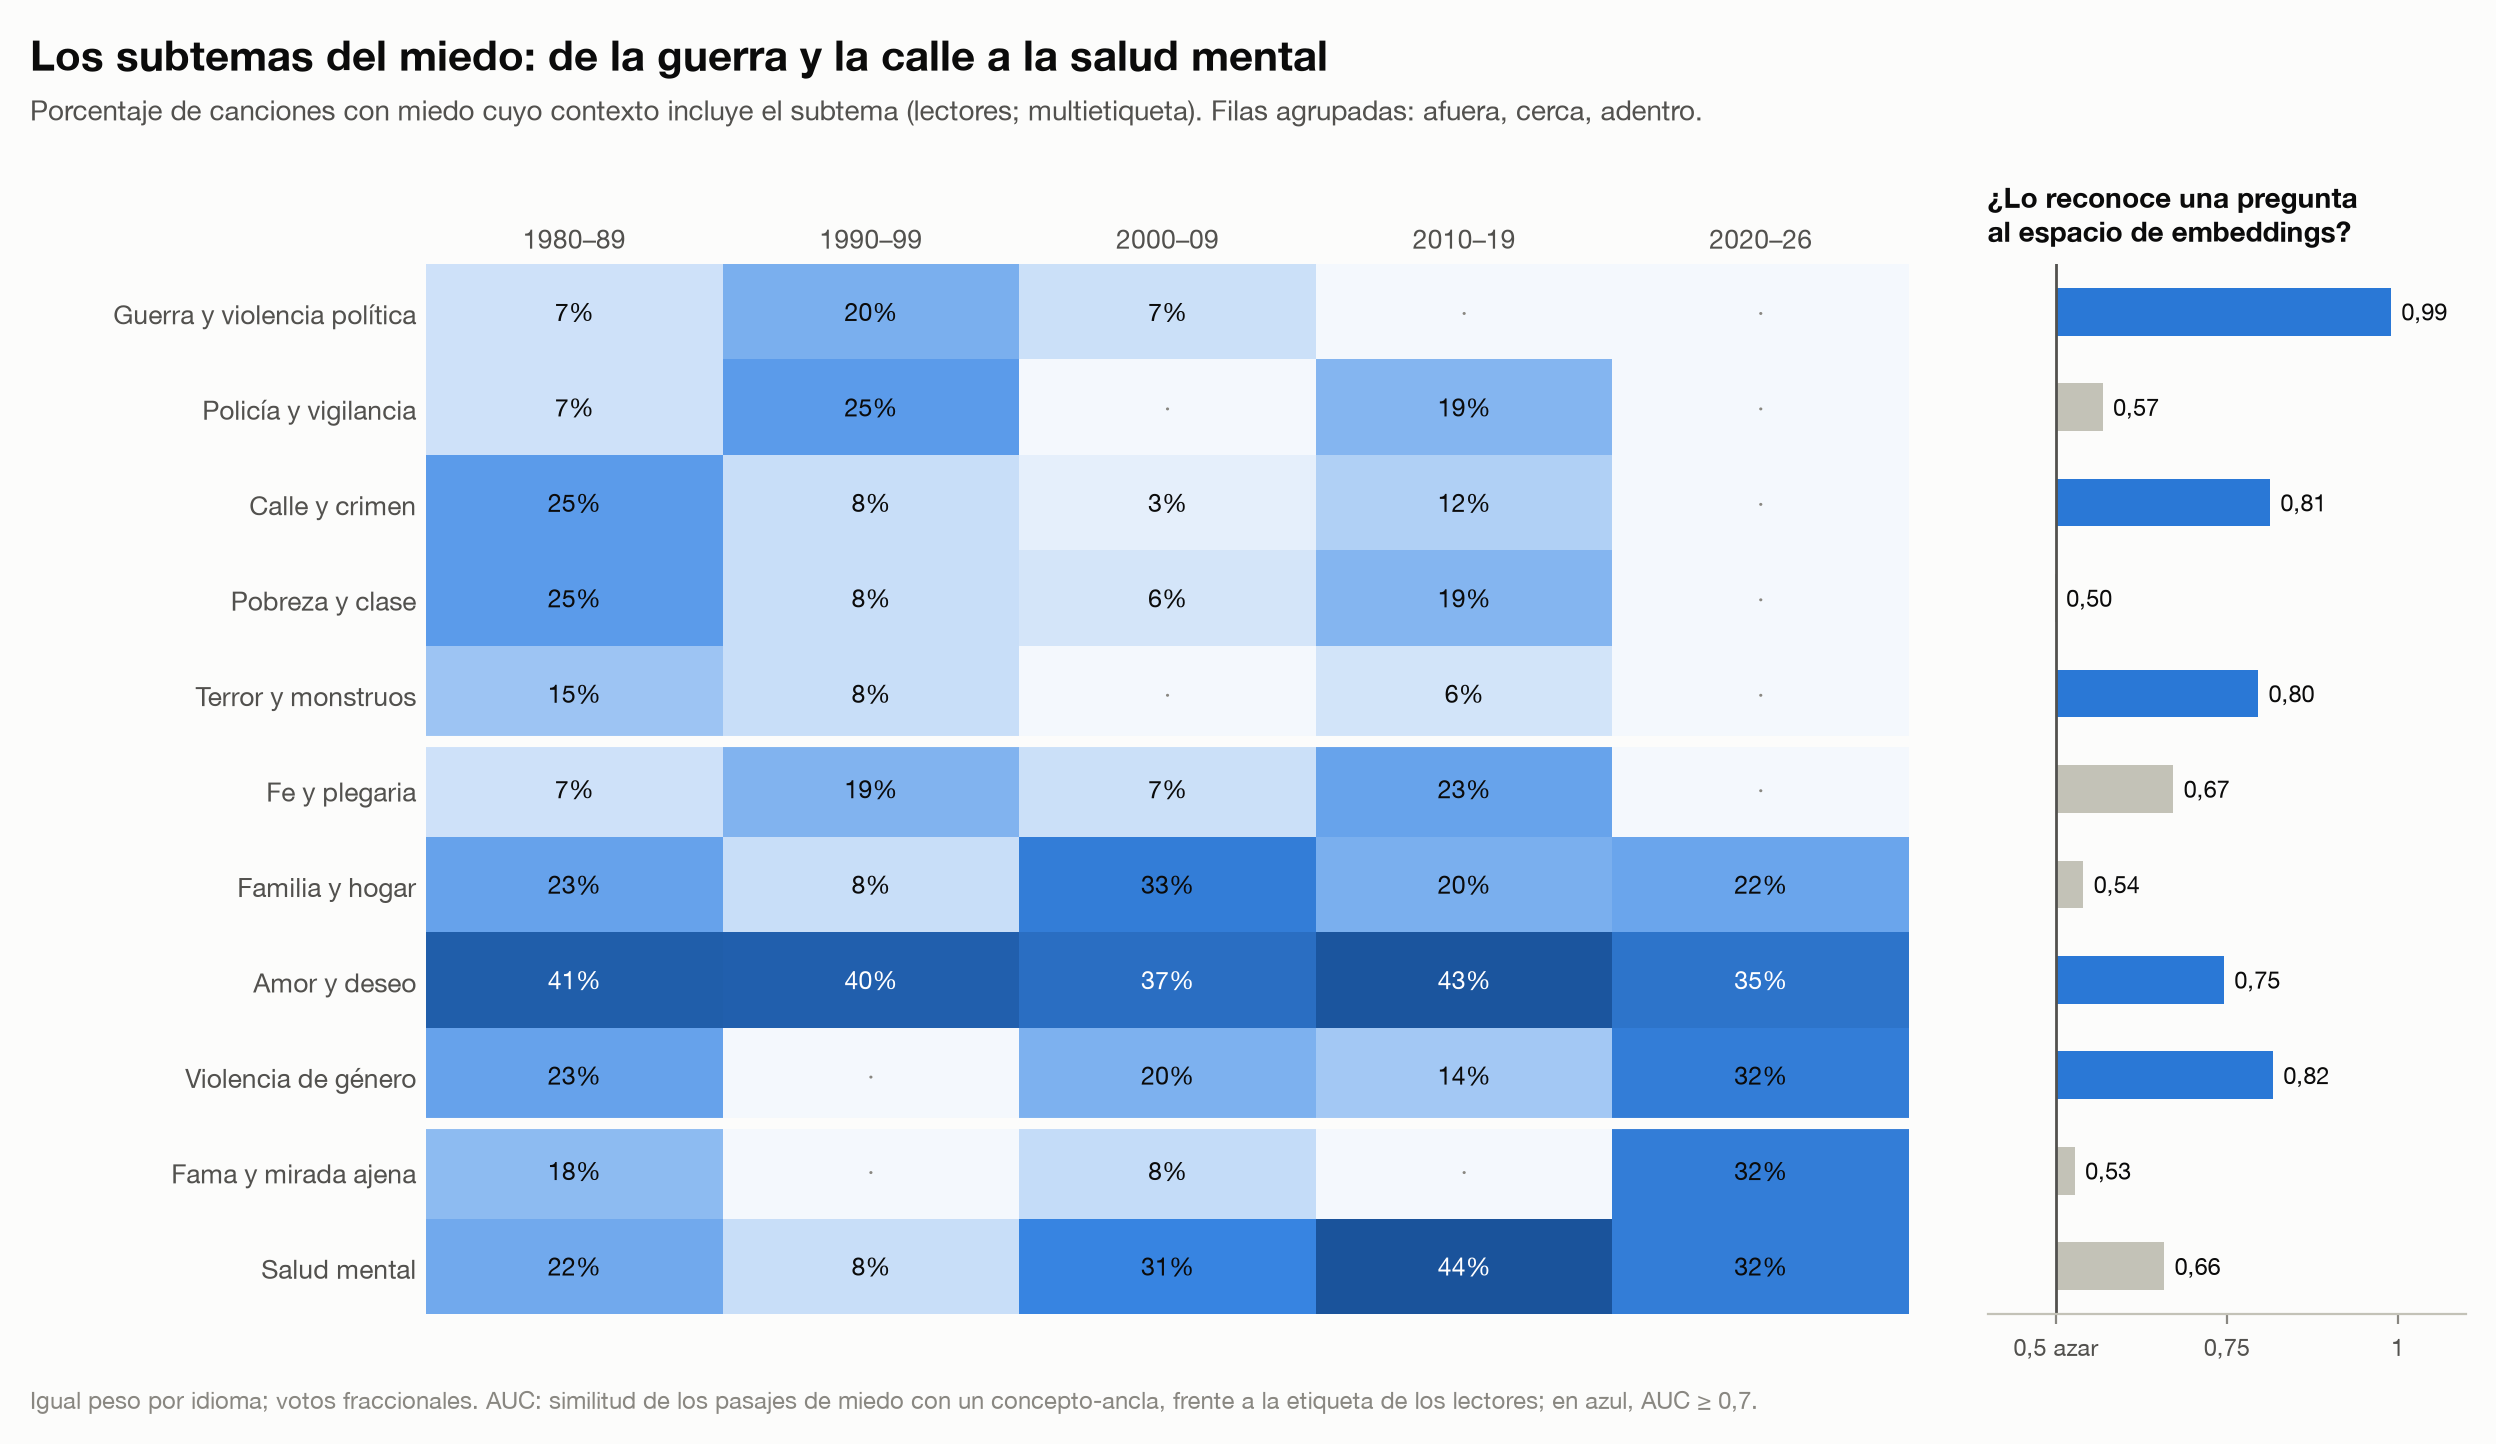

**¿Reconoce una pregunta al espacio cada subtema?** AUC de la similitud con un concepto-ancla frente a la etiqueta de los lectores

,e5_large_fear,e5_large_plain,e5_small,minilm,songs_with_marker
concept,,,,,
guerra_politica,0.99,0.88,0.83,0.82,4
control_pareja,0.82,0.76,0.72,0.73,8
calle_crimen,0.81,0.86,0.81,0.91,7
noche_monstruos,0.80,0.84,0.75,0.70,5
deseo_cuerpo,0.75,0.62,0.60,0.73,22
fe_dios,0.67,0.59,0.57,0.64,8
ansiedad_salud_mental,0.66,0.64,0.63,0.73,19
vigilancia,0.57,0.52,0.61,0.69,5
familia_hogar,0.54,0.62,0.60,0.74,13


In [8]:
fig('fear-subtopics-context', 1000)
cv = pd.read_csv(RES / 'concept_validation.csv')
display(Markdown('**¿Reconoce una pregunta al espacio cada subtema?** AUC de la similitud con un concepto-ancla frente a la etiqueta de los lectores'))
display(cv.pivot(index='concept', columns='encoder', values='auc').join(cv.groupby('concept').songs_with_marker.first())
        .sort_values('e5_large_fear', ascending=False).style.format('{:.2f}', subset=['e5_large_fear', 'e5_large_plain', 'e5_small', 'minilm']))

**Lectura.** Guerra, policía, calle, pobreza y terror ocupan los ochenta y noventa y desaparecen en 2020–26. La salud mental sube a 31–44 % desde 2000. El amor atraviesa todas las décadas (35–43 %): es el contexto más estable del miedo.

Las preguntas al espacio funcionan con escenas concretas (guerra 0,99 con 4 canciones; control en la pareja 0,82; calle 0,81; monstruos 0,80) y fallan con categorías abstractas (pobreza 0,50, fama 0,53, familia 0,54). Un embedding reconoce mejor un escenario que una condición social.

## 6. Embeddings I: el idioma llega primero

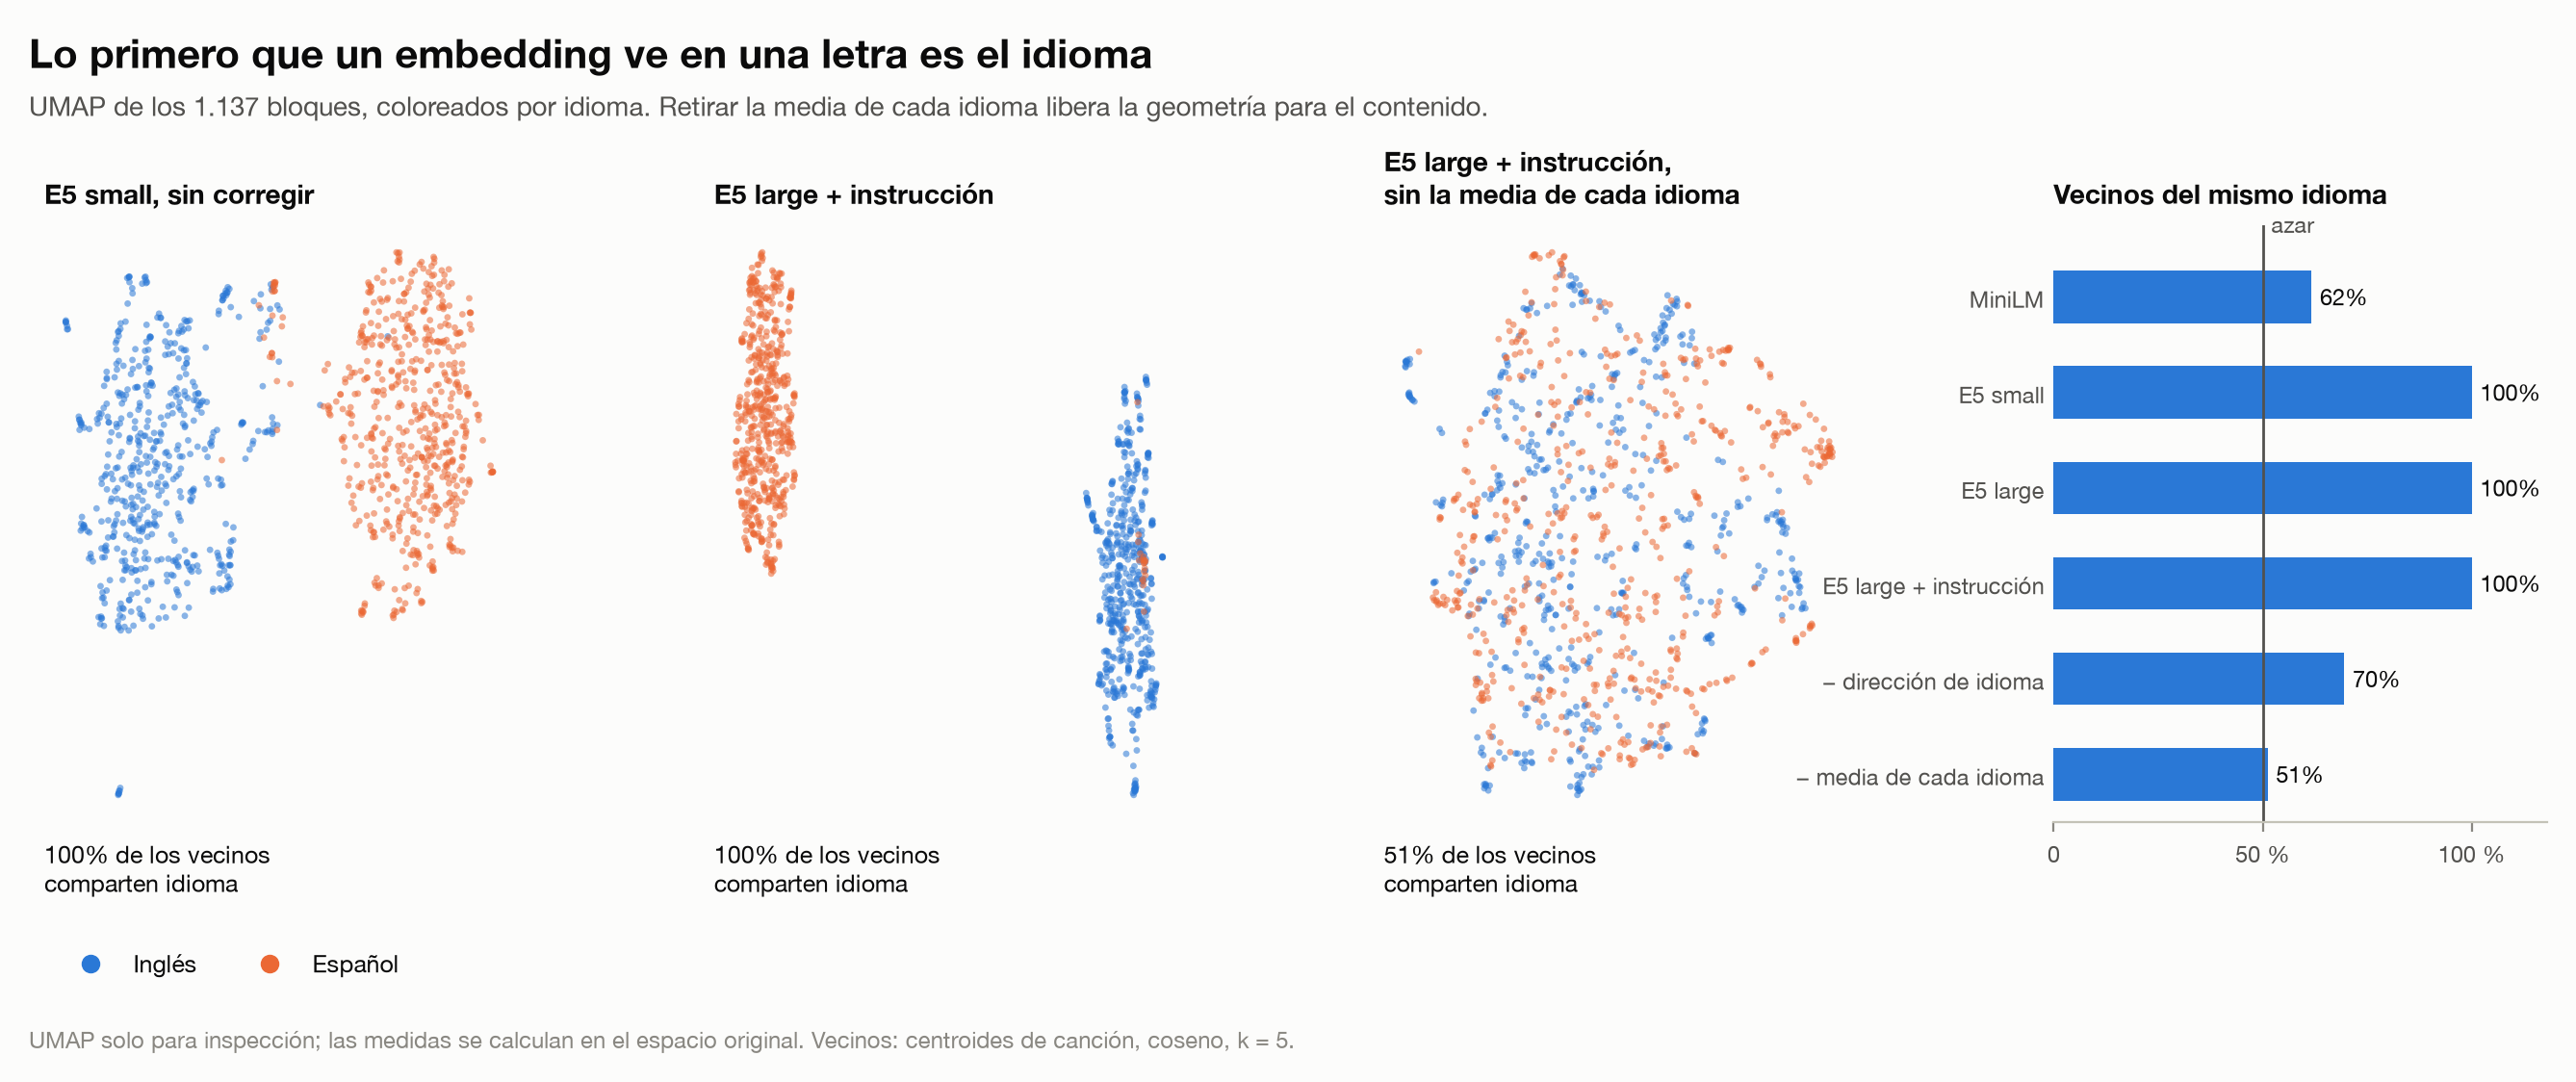

,encoder,variant,same_language_neighbors,fear_status_neighbor_agreement
0,minilm,raw,62%,61%
1,minilm,centered,50%,61%
2,minilm,anchor_projected,62%,61%
3,e5_small,raw,100%,57%
4,e5_small,centered,57%,59%
5,e5_small,anchor_projected,97%,58%
6,e5_large_plain,raw,100%,61%
7,e5_large_plain,centered,52%,63%
8,e5_large_plain,anchor_projected,93%,62%
9,e5_large_fear,raw,100%,64%


In [9]:
fig('fear-language-geometry')
display(pd.read_csv(RES / 'language_neighbors.csv').style.format({'same_language_neighbors': '{:.0%}', 'fear_status_neighbor_agreement': '{:.0%}'}))

**Lectura.** Sin corrección, los cinco vecinos de cada canción comparten idioma en E5 small y E5 large: el mapa separa inglés de español antes que cualquier miedo. Retirar la media de cada idioma (Libovický et al., 2020) devuelve la proporción al azar (51 %). La instrucción de miedo, sola, no lo resuelve, pero combinada con una dirección de idioma estimada con anclas paralelas reduce la señal a 70 % sin borrar diferencias reales de contenido entre corpus.

## 7. Embeddings II: el mapa libre no responde la pregunta

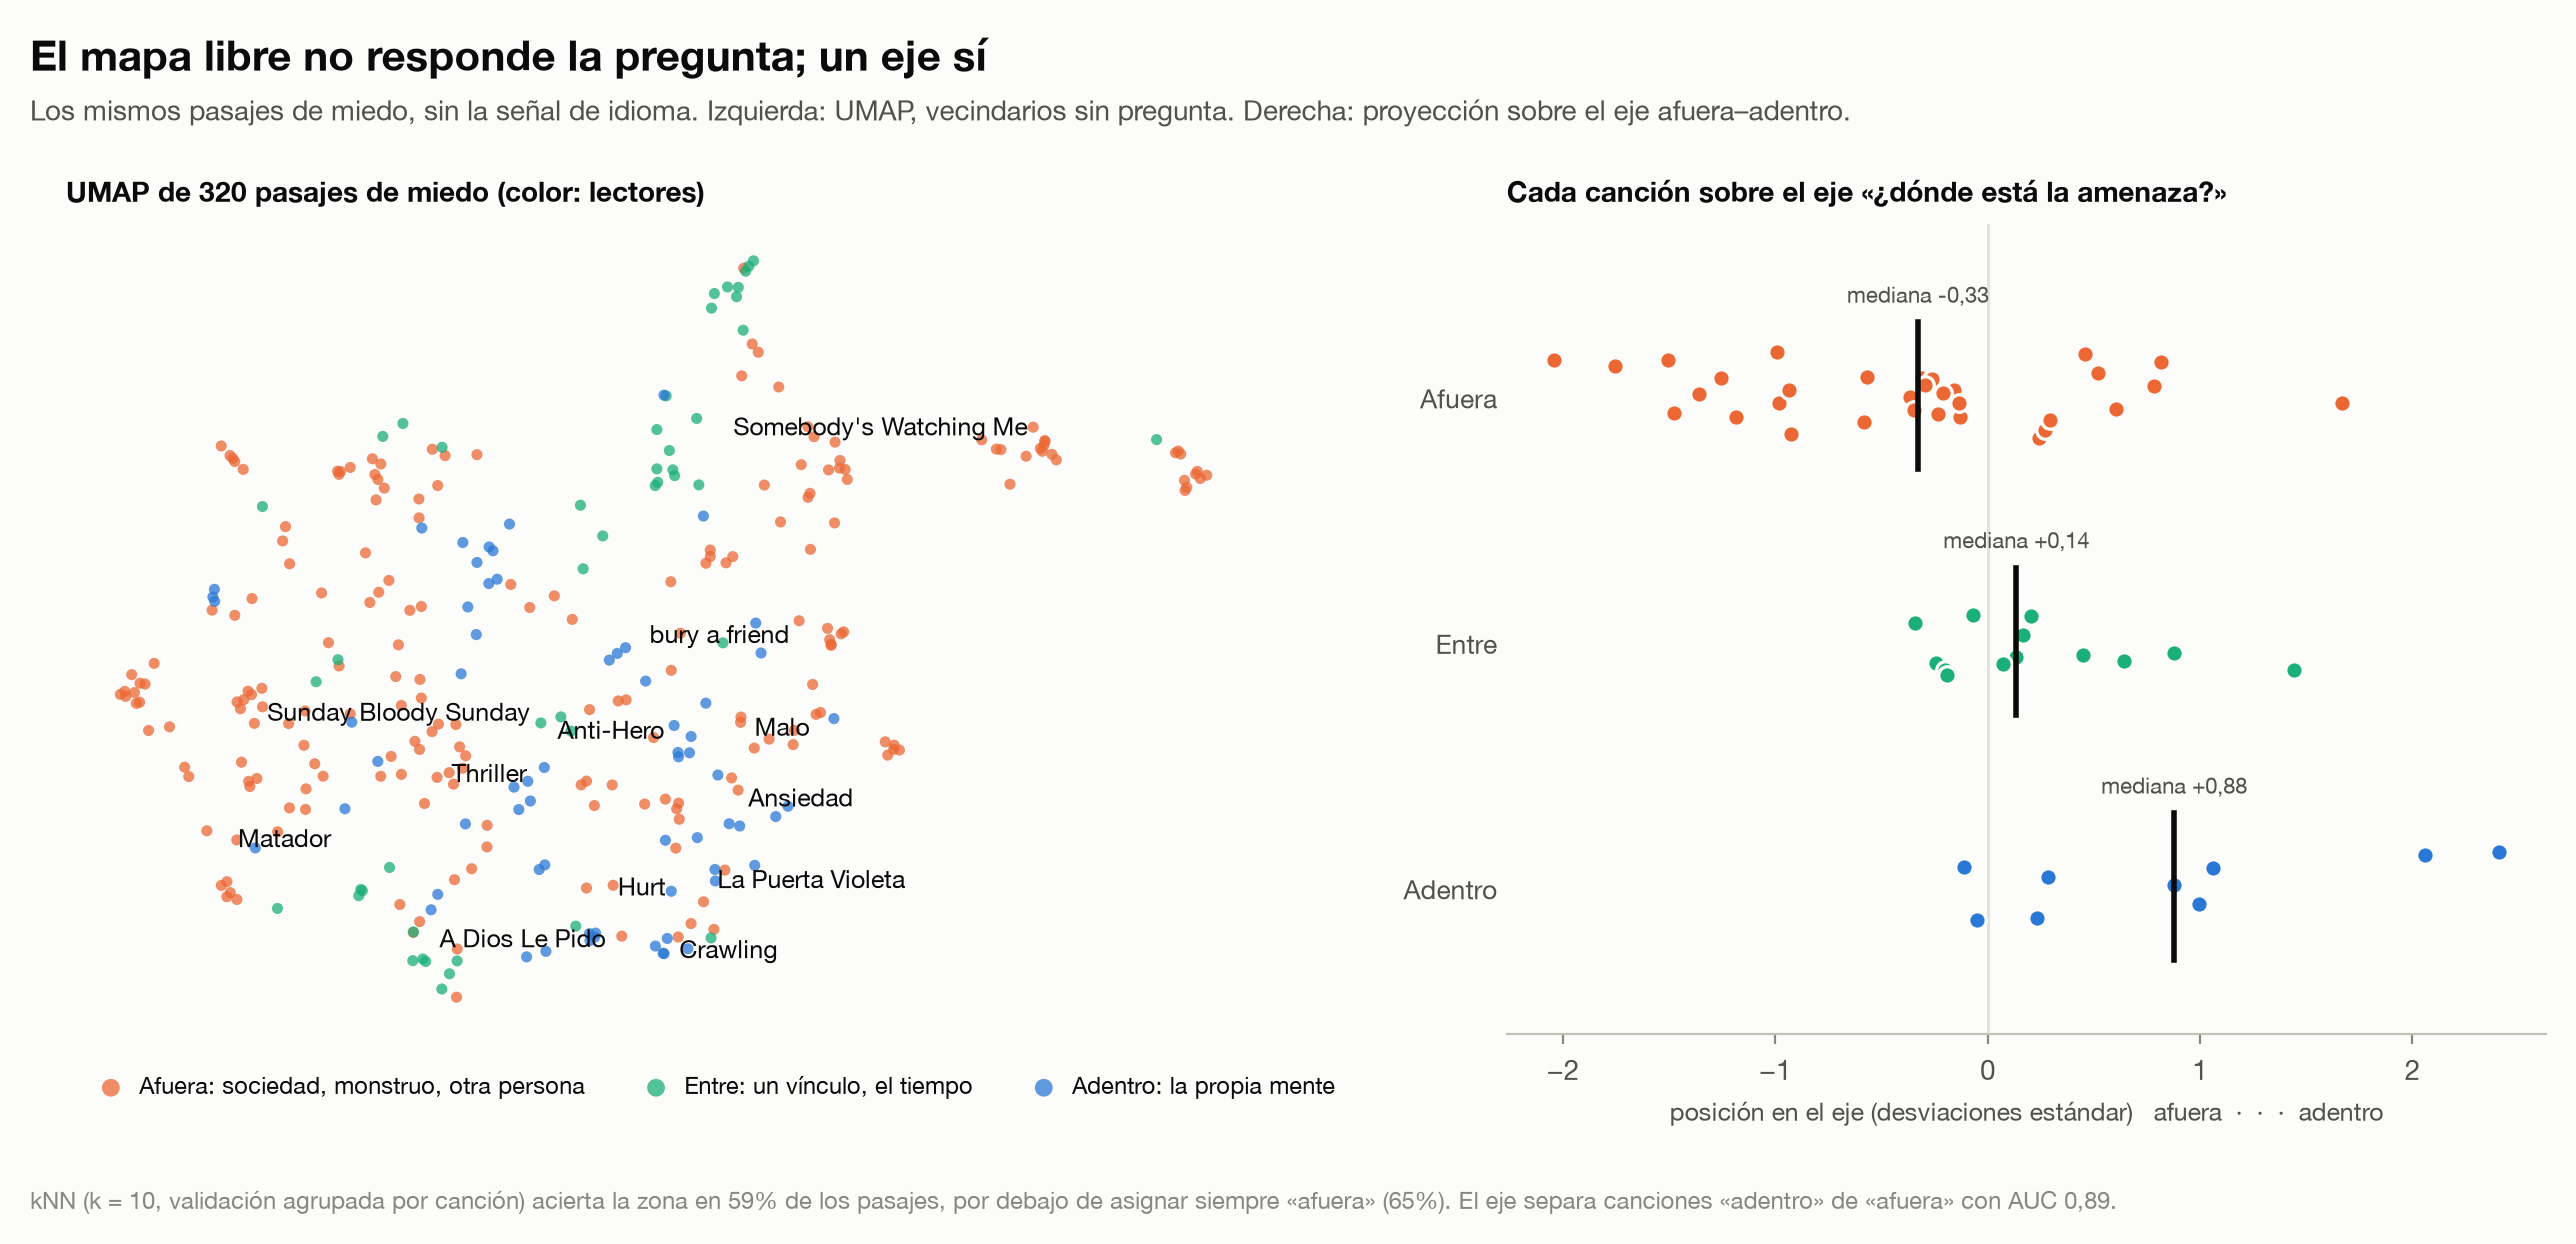

**Agrupamiento libre de canciones (Ward) frente a las lecturas, el idioma y su estabilidad bootstrap**

,encoder,variant,k,songs,nmi_reader_locus,ari_reader_locus,nmi_language,bootstrap_ari
0,minilm,raw,6,56,0.18,-0.02,0.07,0.33
1,minilm,raw,8,56,0.25,-0.00,0.08,0.36
2,minilm,centered,6,56,0.28,0.07,0.00,0.38
3,minilm,centered,8,56,0.28,0.04,0.01,0.40
4,e5_small,raw,6,56,0.15,-0.03,0.63,0.67
5,e5_small,raw,8,56,0.17,-0.02,0.58,0.66
6,e5_small,centered,6,56,0.22,0.02,0.07,0.40
7,e5_small,centered,8,56,0.30,0.05,0.15,0.47
8,e5_large_plain,raw,6,56,0.25,0.07,0.57,0.56
9,e5_large_plain,raw,8,56,0.28,0.08,0.54,0.58


,encoder,variant,knn10_zone_accuracy,majority_baseline
0,minilm,raw,53%,65%
1,minilm,centered,53%,65%
2,e5_small,raw,52%,65%
3,e5_small,centered,60%,65%
4,e5_large_plain,raw,54%,65%
5,e5_large_plain,centered,63%,65%
6,e5_large_fear,raw,48%,65%
7,e5_large_fear,centered,59%,65%


In [10]:
fig('fear-map-vs-question')
clus = pd.read_csv(RES / 'clustering_vs_readers.csv')
display(Markdown('**Agrupamiento libre de canciones (Ward) frente a las lecturas, el idioma y su estabilidad bootstrap**'))
display(clus.style.format({c: '{:.2f}' for c in ['nmi_reader_locus', 'ari_reader_locus', 'nmi_language', 'bootstrap_ari']}))
display(pd.read_csv(RES / 'knn_zone_check.csv').style.format({'knn10_zone_accuracy': '{:.0%}', 'majority_baseline': '{:.0%}'}))

**Lectura.** Esta es la razón por la que la versión anterior del estudio se sentía vaga. Sin corrección, el agrupamiento parece estable (ARI bootstrap ≈ 0,6) porque agrupa por idioma (NMI con idioma ≈ 0,6). Sin idioma, la estabilidad cae a ≈ 0,4 y el acuerdo con el lugar de la amenaza queda en NMI ≈ 0,3. Los vecinos más próximos de un pasaje comparten escena, vocabulario o estribillo, no el lugar de la amenaza: kNN acierta menos que asignar siempre «afuera».

BERTopic y UMAP siguen siendo útiles para explorar, pero no para medir un concepto que no les preguntamos.

## 8. Embeddings III: preguntar con ejes

Cada eje es la diferencia entre dos polos de 16 frases ancla (8 EN, 8 ES, traducciones paralelas, todas en primera persona y con miedo explícito, para aislar la dimensión). Archivo: `semantic-anchors.json`. Método: Kozlowski, Taddy y Evans (2019); An, Kwak y Ahn (2018).

In [11]:
loo = pd.read_csv(RES / 'axis_anchor_loo.csv').pivot(index='encoder', columns='axis', values='loo_accuracy')
display(Markdown('**Validación interna**: cada par de anclas proyectado sobre un eje construido sin él'))
display(loo.style.format('{:.0%}'))
av = pd.read_csv(RES / 'axis_validation.csv')
display(Markdown('**Validación externa**: AUC de cada eje frente a las categorías de los lectores'))
display(av.pivot(index='encoder', columns='axis', values='auc').style.format('{:.2f}'))

**Validación interna**: cada par de anclas proyectado sobre un eje construido sin él

axis,agencia,colectividad,interiorizacion
encoder,,,
e5_large_fear,97%,100%,100%
e5_large_plain,100%,100%,97%
e5_small,69%,100%,94%
minilm,75%,100%,94%


**Validación externa**: AUC de cada eje frente a las categorías de los lectores

axis,agencia,colectividad,interiorizacion
encoder,,,
e5_large_fear,0.72,0.85,0.89
e5_large_plain,0.69,0.80,0.85
e5_small,0.69,0.73,0.79
minilm,0.54,0.77,0.77


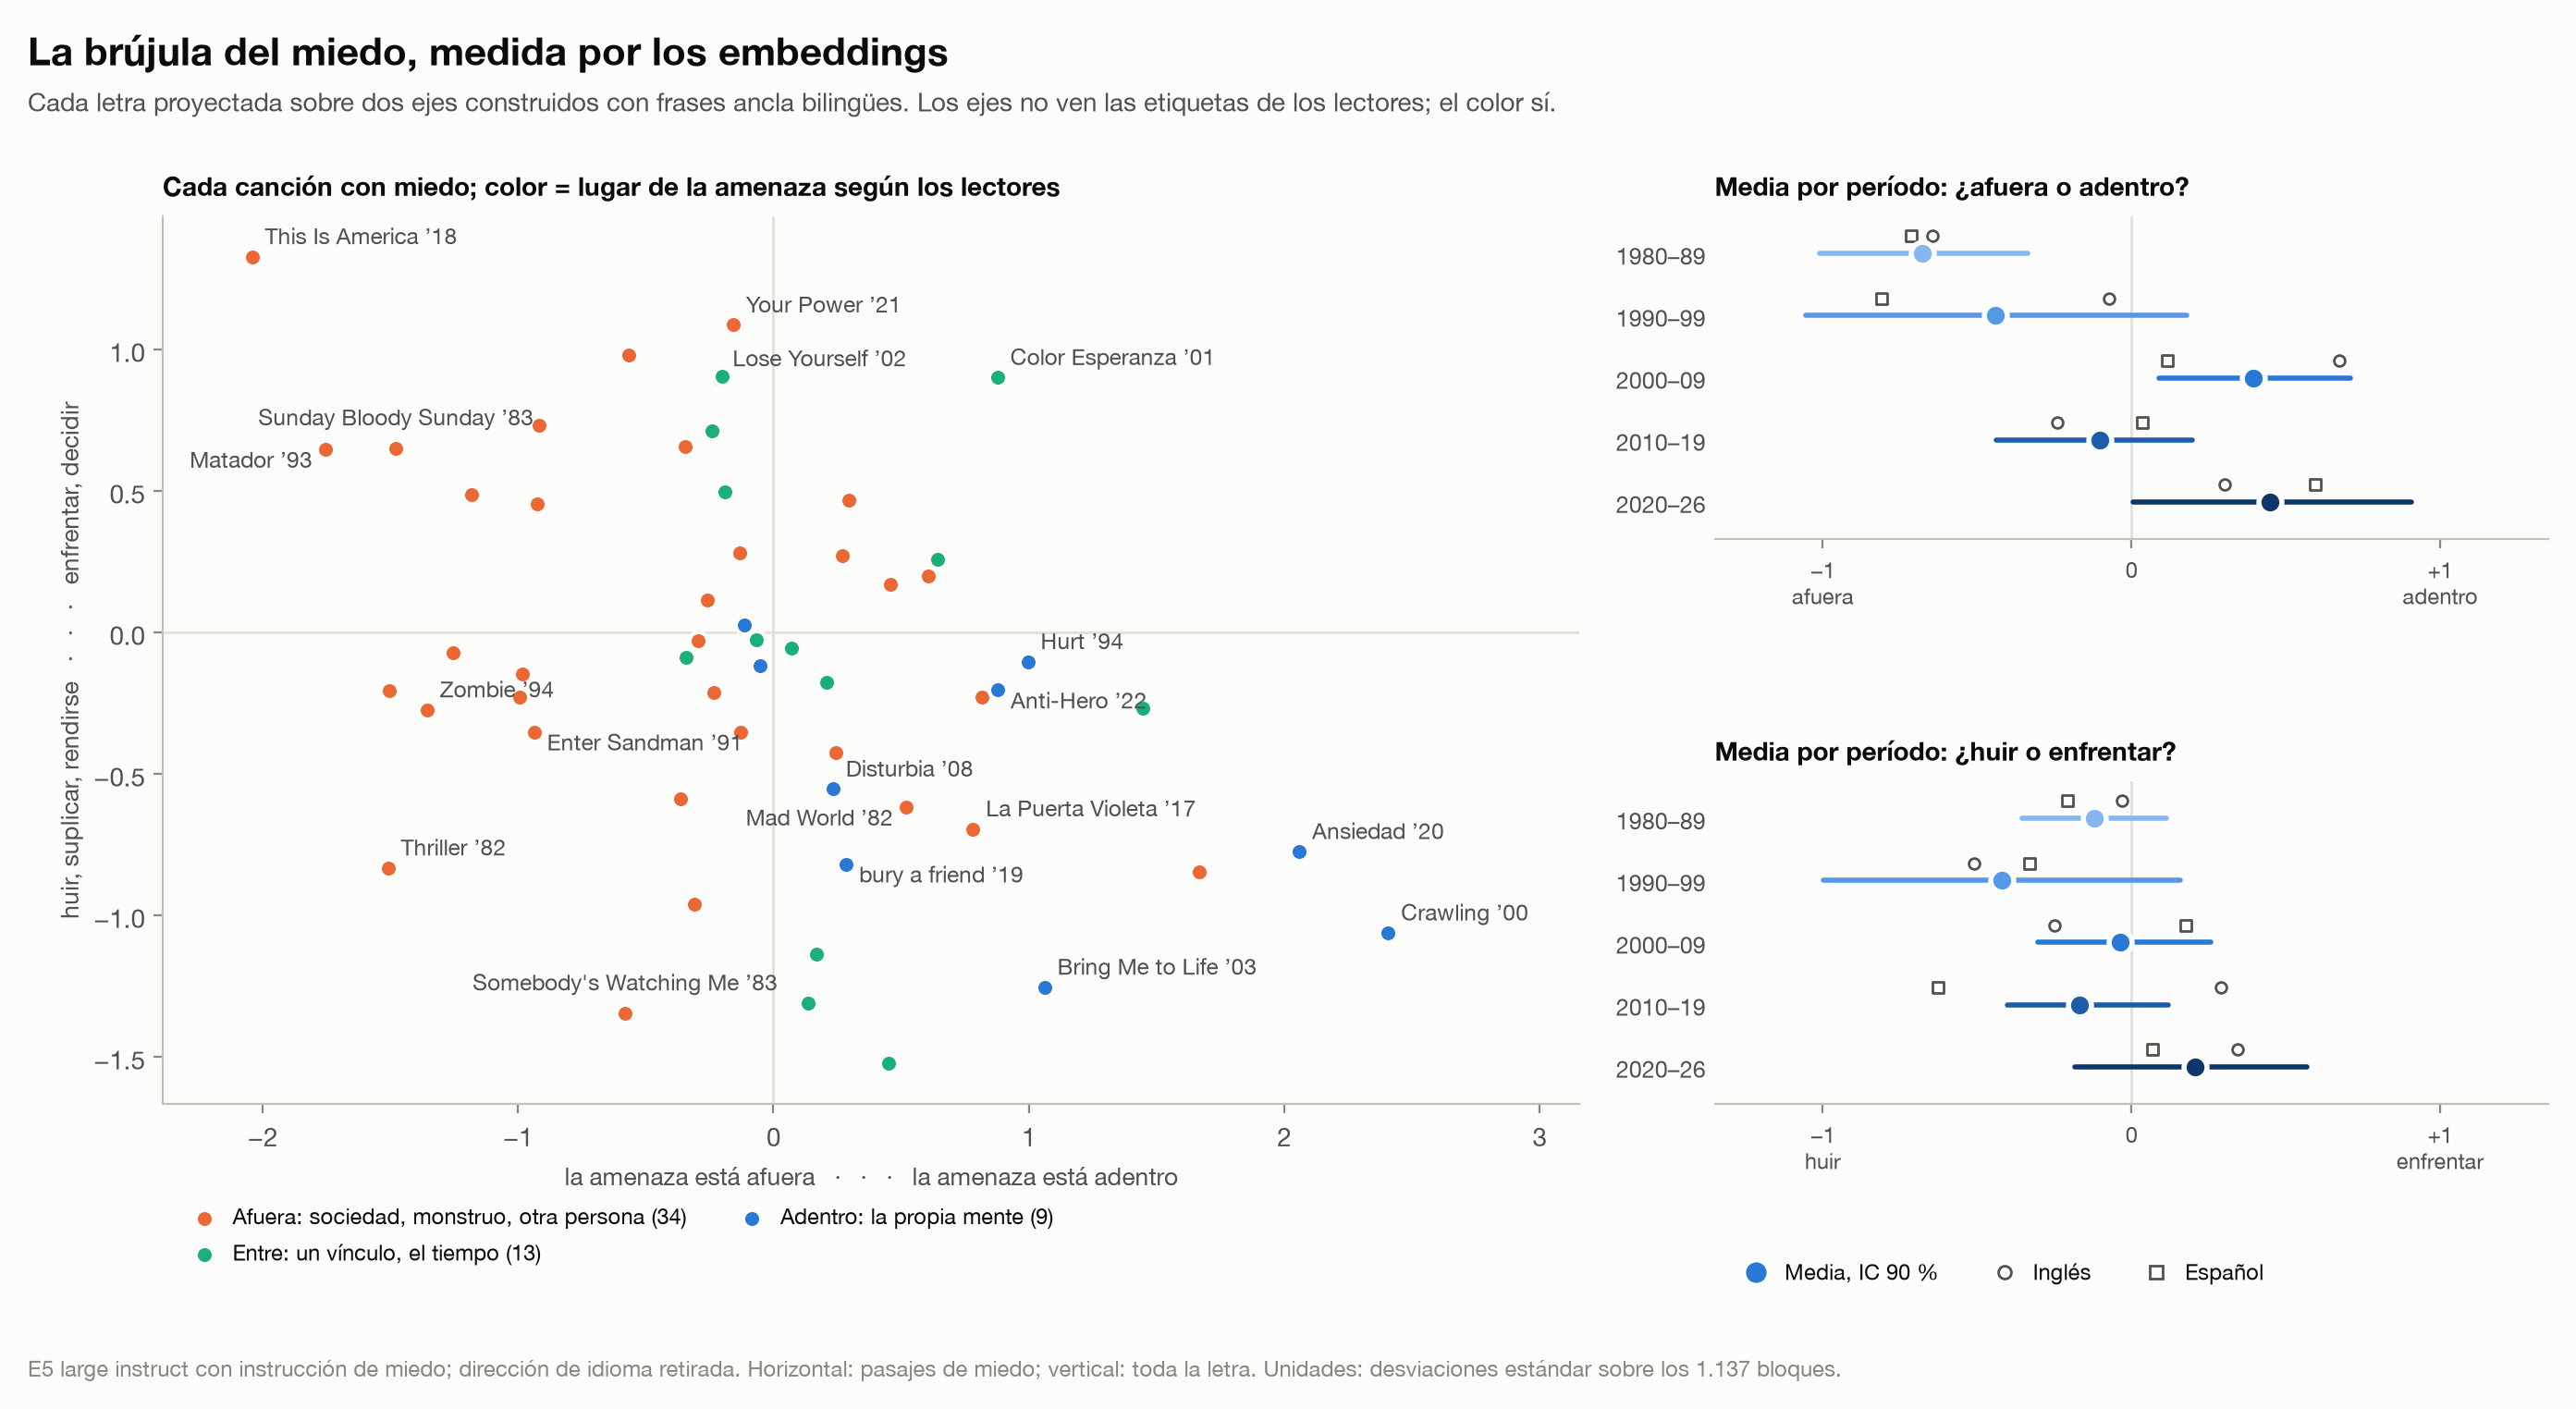

,measure,slope_per_decade,p_two_sided
9,eje: interiorización (bloques de miedo),+0.23,0.013
10,eje: agencia (toda la letra),+0.09,0.208
11,eje: colectividad (bloques de miedo),-0.07,0.401


In [12]:
fig('fear-compass', 1150)
display(trends[trends.measure.str.startswith('eje')][['measure', 'slope_per_decade', 'p_two_sided']].style.format({'slope_per_decade': '{:+.2f}', 'p_two_sided': '{:.3f}'}))

**Lectura.** El encoder instruido es el mejor en los tres ejes (afuera/adentro 0,89; colectivo 0,85; huir/enfrentar 0,72), y la instrucción mejora 0,02–0,05 sobre el mismo modelo sin ella. Sin mirar etiquetas, el eje afuera→adentro se desplaza +0,23 desviaciones estándar por década. El eje de agencia apenas se mueve (p = 0,21): la geometría capta mejor **dónde** está la amenaza que **cómo** responde la voz.

## 9. Arcos argumentales

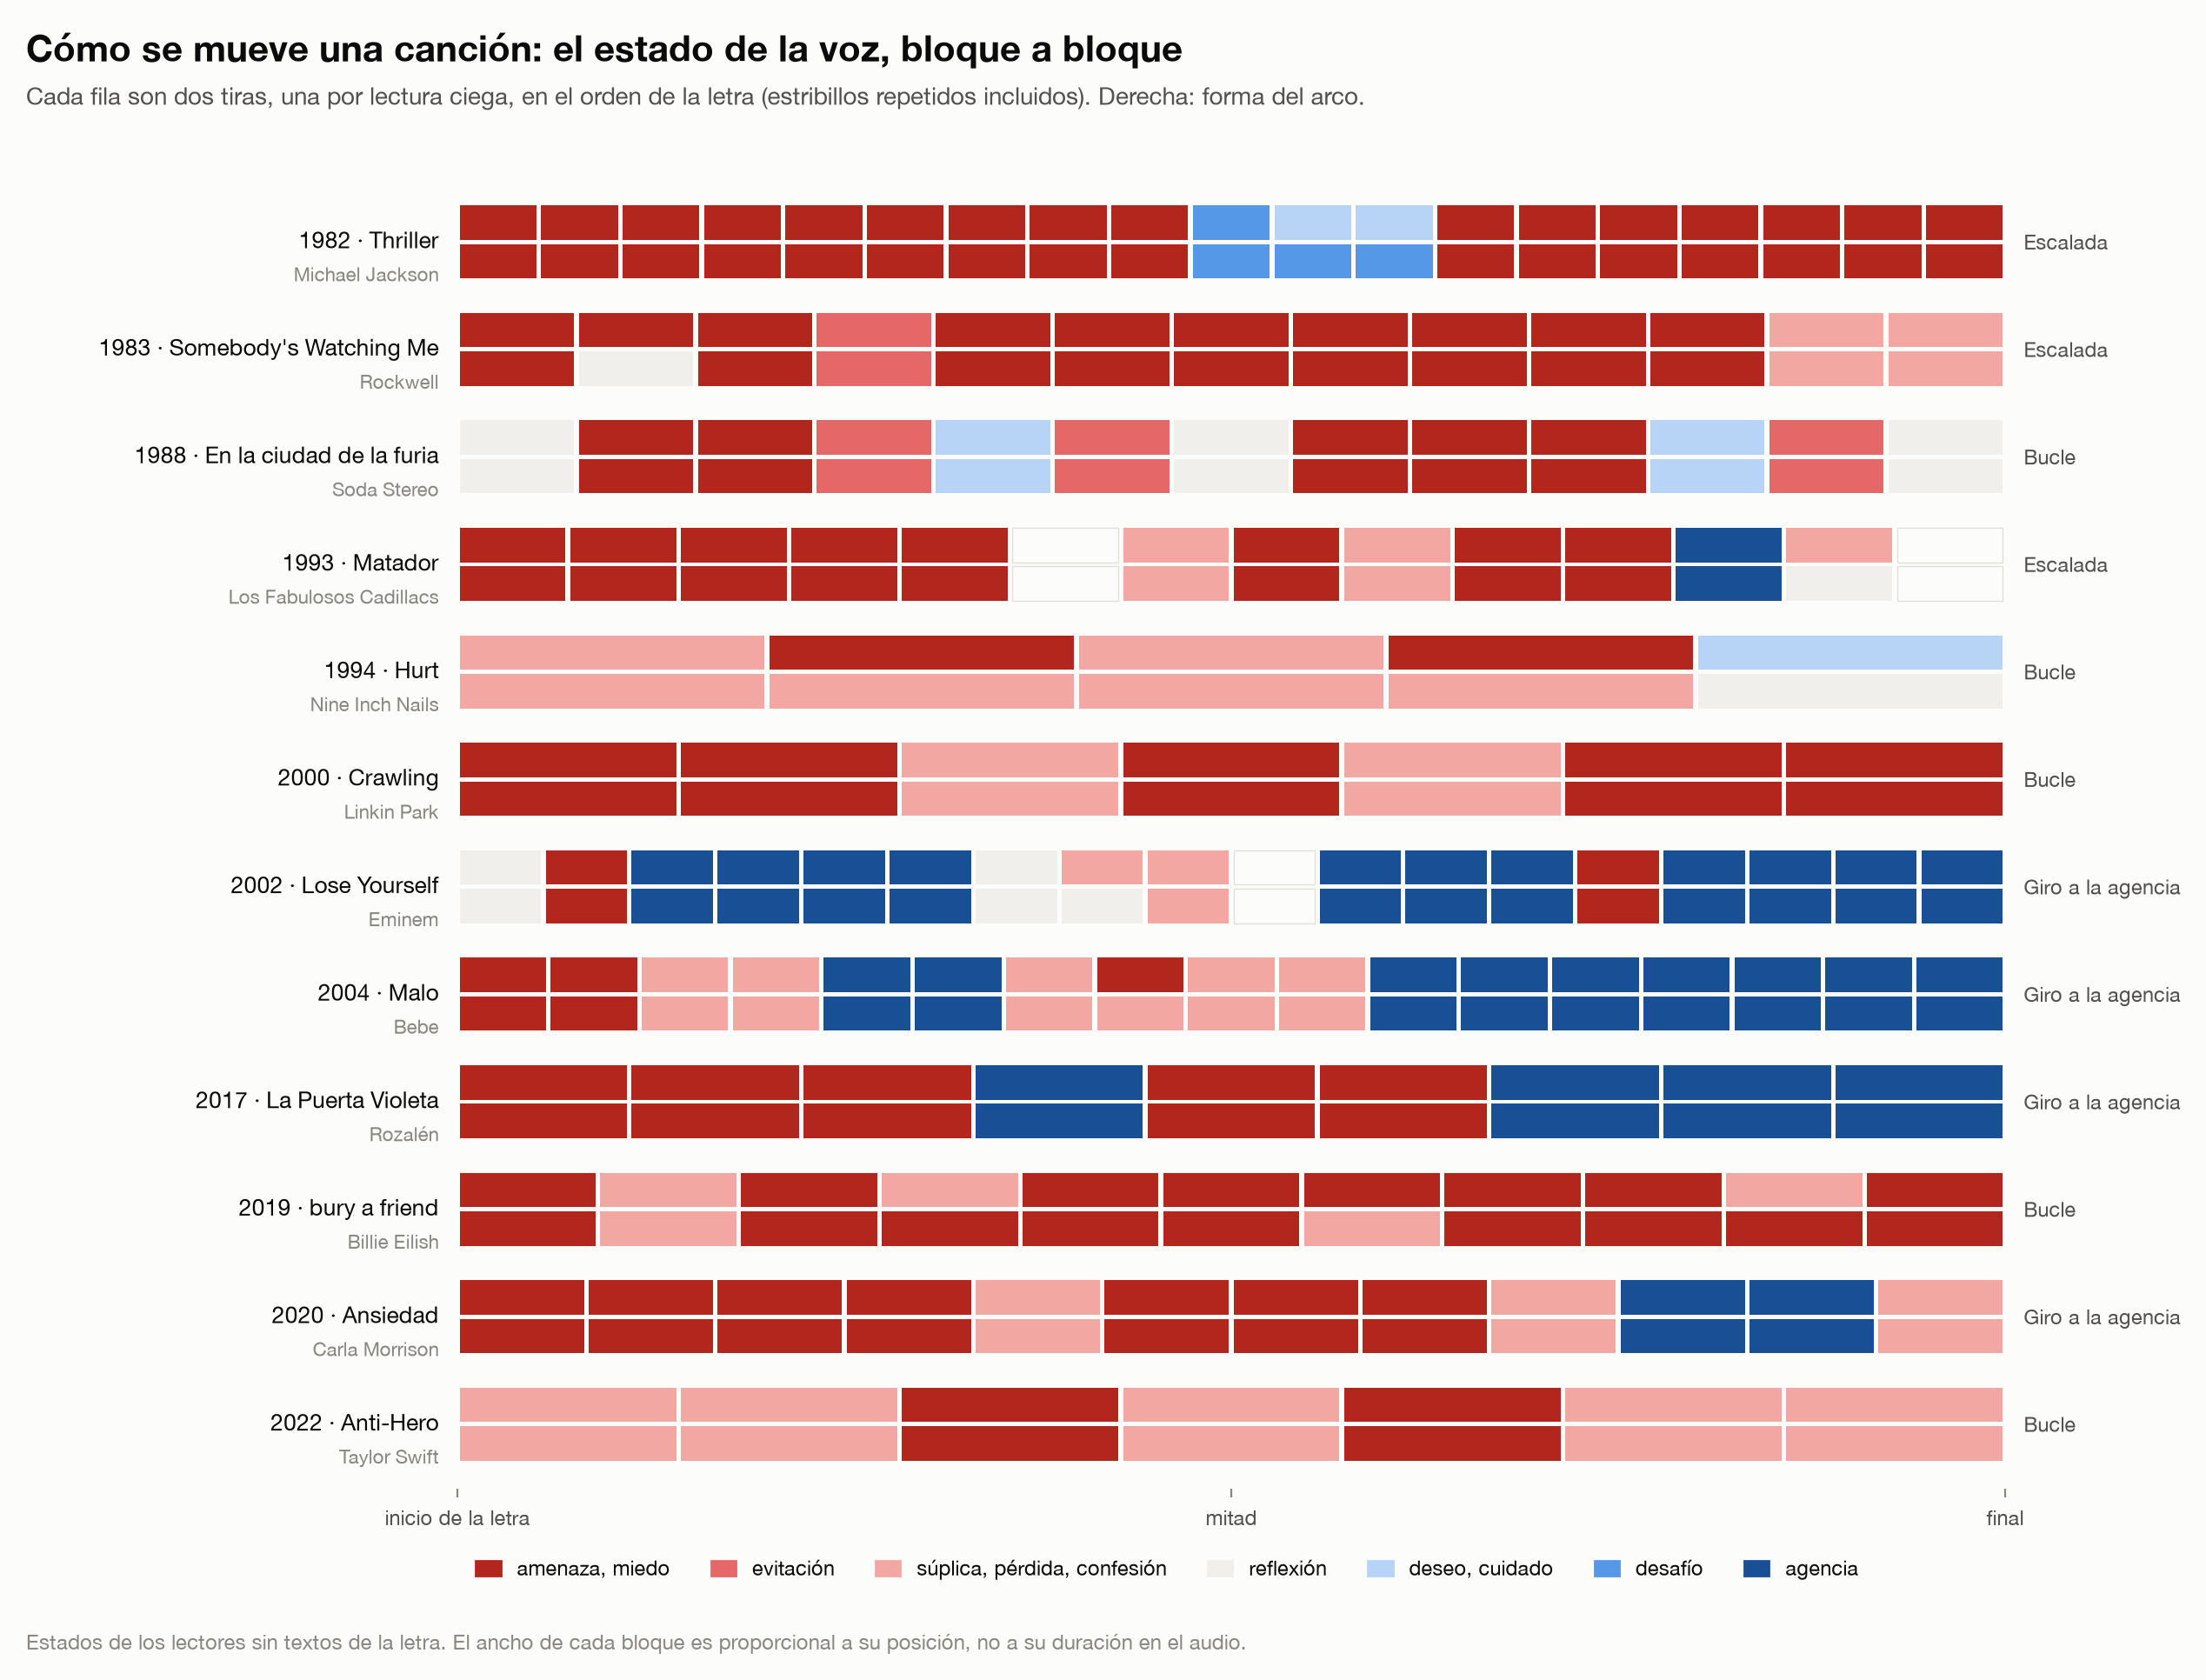

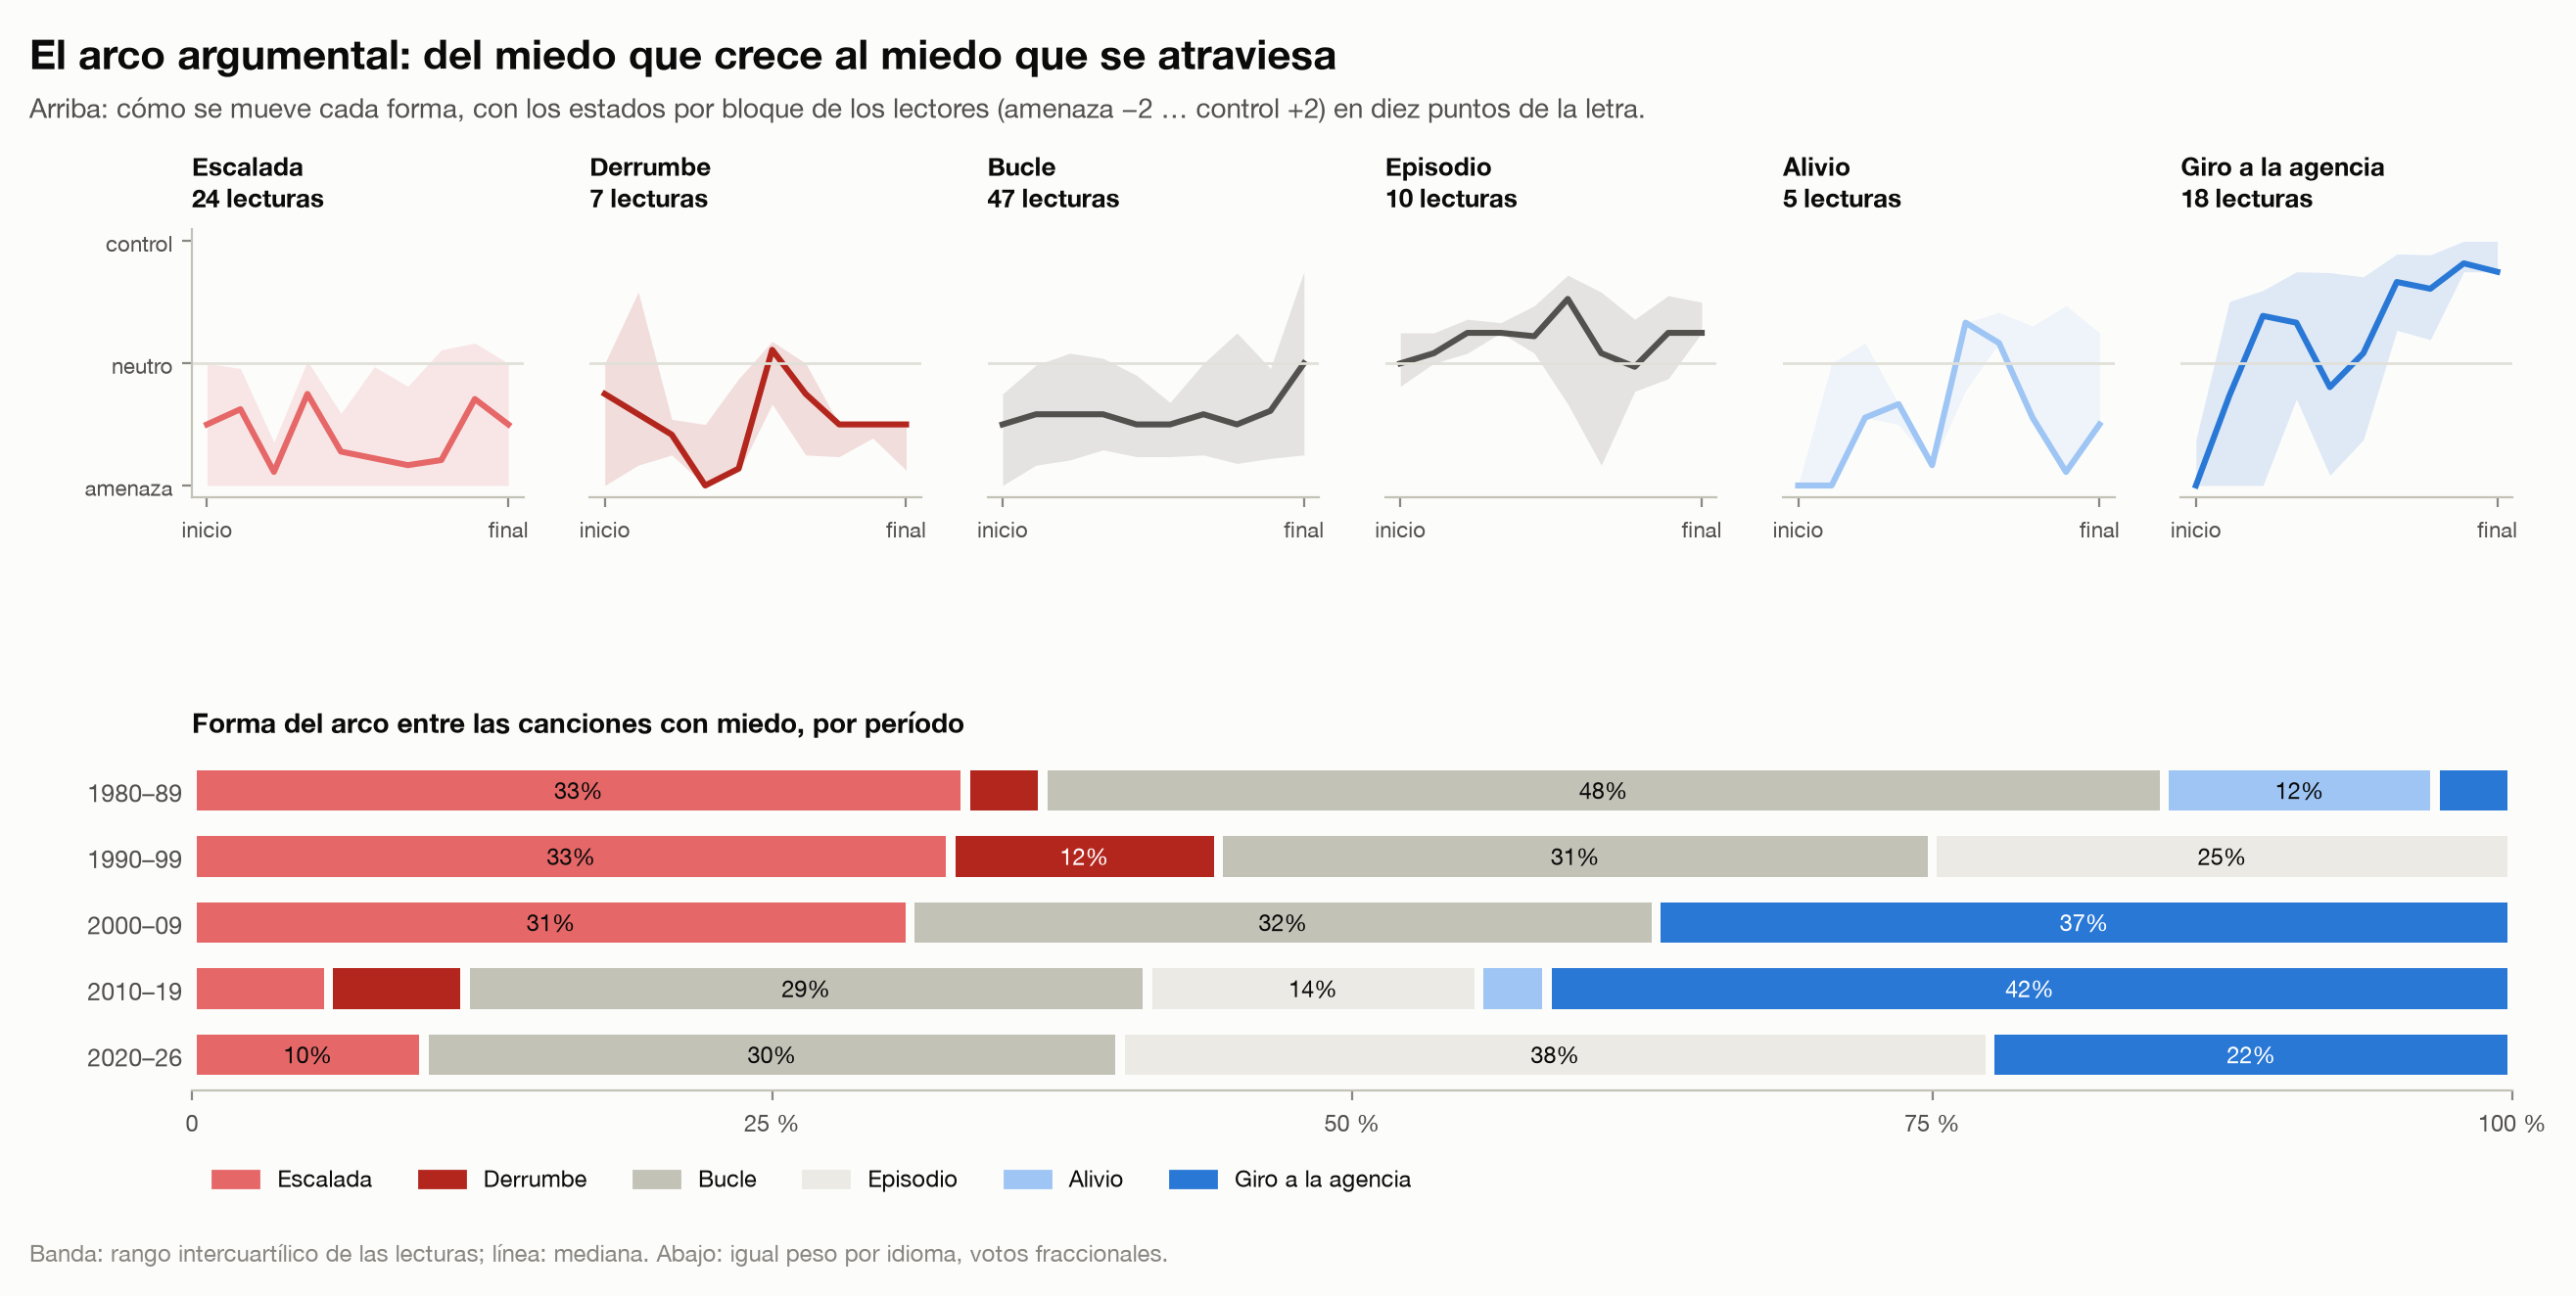

,measure,slope_per_decade,p_two_sided
6,lectura: respuesta de confesión,+3.6%,0.291
7,lectura: respuesta de enfrentar/decidir,+8.7%,0.075
8,lectura: respuesta de huir/someterse,-2.6%,0.554
12,arco: giro a la agencia,+6.5%,0.077
13,arco: escalada,-7.7%,0.063
14,arco: bucle,-2.8%,0.501
15,arco: episodio,+6.9%,0.014


**¿Sigue la geometría el movimiento dentro de una canción?** Correlación de Spearman entre el estado de los lectores y el eje de agencia, bloque a bloque

songs                        116.000000
mean_within_song_spearman      0.153194
share_positive                 0.672414
pooled_block_spearman          0.317613
dtype: float64

In [13]:
fig('fear-story-strips')
fig('fear-arcs')
display(trends[trends.measure.str.startswith('arco') | trends.measure.str.startswith('lectura: respuesta')]
        [['measure', 'slope_per_decade', 'p_two_sided']].style.format({'slope_per_decade': '{:+.1%}', 'p_two_sided': '{:.3f}'}))
display(Markdown('**¿Sigue la geometría el movimiento dentro de una canción?** Correlación de Spearman entre el estado de los lectores y el eje de agencia, bloque a bloque'))
display(pd.Series(json.loads((RES / 'arc_embedding_validation.json').read_text())))

**Lectura.** En los ochenta y noventa, un tercio de las canciones con miedo escala: la amenaza crece hasta el final (*Thriller*, *Somebody's Watching Me*, *Matador*). Desde 2000, entre un tercio y dos quintos dan un **giro a la agencia**: la voz termina enfrentando o decidiendo (*Lose Yourself*, *Malo*, *La Puerta Violeta*, *Ansiedad*). El **bucle** persiste en todas las décadas (~30 %): el estribillo como obsesión que no se resuelve (*Mad World*, *Crawling*, *bury a friend*, *Anti-Hero*). En 2020–26 crece el miedo **episódico**: un instante de vértigo dentro de una canción de amor.

Los embeddings siguen ese movimiento débilmente (ρ medio 0,15 dentro de la canción): el arco necesita lectura, no solo vectores.

## 10. Qué protege la voz

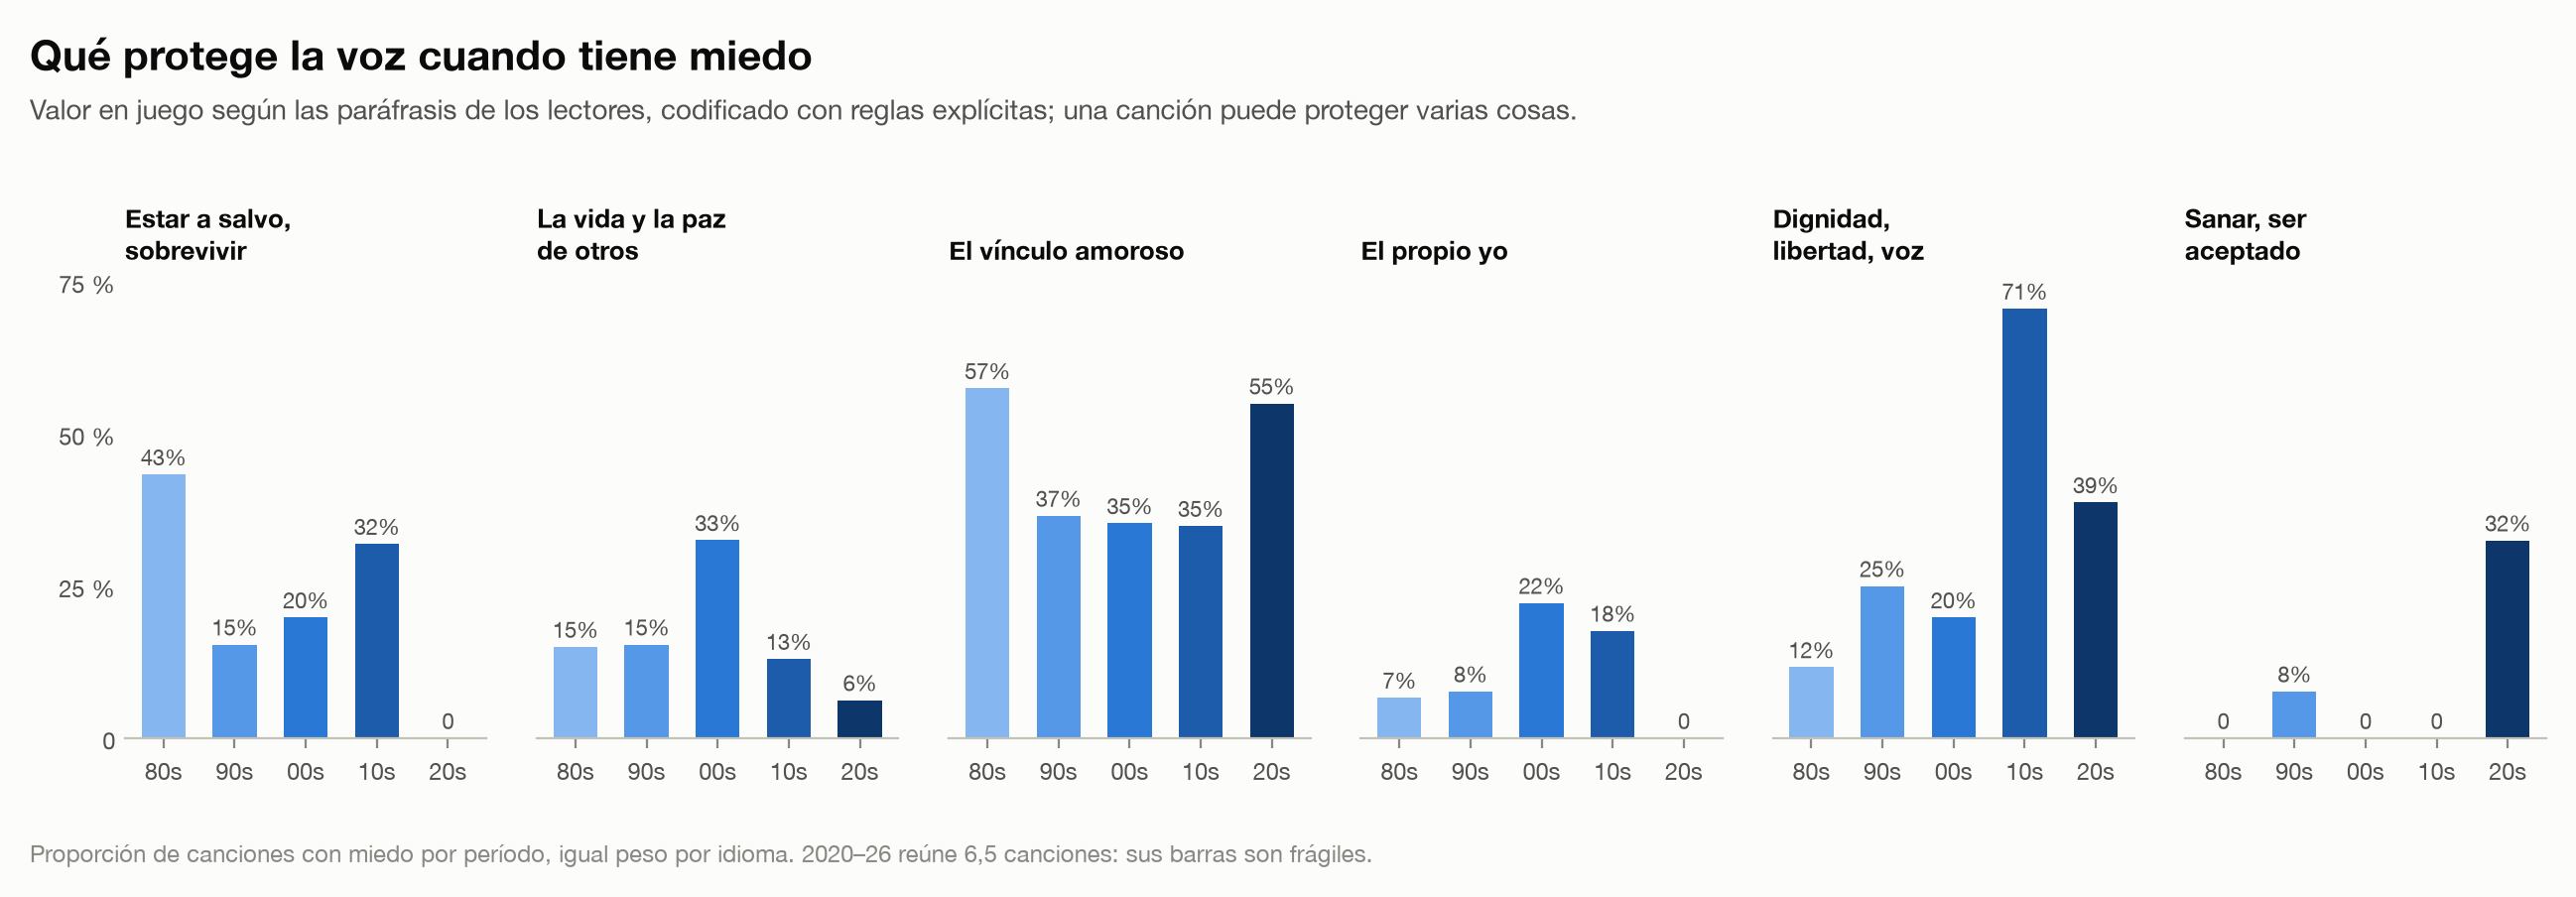

,1980–89,1990–99,2000–09,2010–19,2020–26
"Estar a salvo, sobrevivir",43%,15%,20%,32%,0%
La vida y la paz de otros,15%,15%,33%,13%,6%
El vínculo amoroso,57%,37%,35%,35%,55%
El propio yo,7%,8%,22%,18%,0%
"Dignidad, libertad, voz",12%,25%,20%,71%,39%
"Sanar, ser aceptado",0%,8%,0%,0%,32%


In [14]:
fig('fear-values')
display(pd.read_csv(RES / 'values_by_period.csv', index_col=0).rename(columns=lambda c: PLAB[int(c)]).style.format('{:.0%}'))

**Lectura.** «Estar a salvo» (privacidad, refugio, sobrevivir) domina los ochenta y desaparece en 2020–26. «Dignidad, libertad, voz» alcanza 71 % en 2010–19. «Sanar, ser aceptado» solo aparece en la última década (*Ansiedad*, *Anti-Hero*). El vínculo amoroso es lo que más se protege en casi todos los períodos. La codificación es una regla de palabras clave sobre paráfrasis (`VALUES` en `fear_story.py`): describe las lecturas, no las mide de forma independiente.

## 11. Sensibilidad: ¿qué resiste?

In [15]:
sens = pd.read_csv(RES / 'trend_sensitivity.csv')
display(sens.style.format({'slope_per_decade': '{:+.3f}', 'p_two_sided': '{:.3f}'}))

,subset,column,slope_per_decade,p_two_sided,songs,weight
0,miedo acordado por ambos lectores,threat_locus:internal_self,+0.092,0.013,50,50.000000
1,miedo acordado por ambos lectores,threat_locus:external_collective,-0.135,0.008,50,50.000000
2,miedo acordado por ambos lectores,interiorizacion_fear,+0.250,0.013,50,50.000000
3,miedo acordado por ambos lectores,agentic,+0.086,0.092,50,50.000000
4,miedo acordado por ambos lectores,agencia_all,+0.097,0.190,50,50.000000
5,excluye canciones elegidas como «miedo»,threat_locus:internal_self,+0.035,0.365,32,29.000000
6,excluye canciones elegidas como «miedo»,threat_locus:external_collective,-0.109,0.142,32,29.000000
7,excluye canciones elegidas como «miedo»,interiorizacion_fear,+0.199,0.071,32,29.000000
8,excluye canciones elegidas como «miedo»,agentic,+0.103,0.140,32,29.000000
9,excluye canciones elegidas como «miedo»,agencia_all,+0.036,0.720,32,29.000000


**Lectura.**

- **Resiste:** con solo las 50 canciones de miedo acordado, todas las tendencias se mantienen o se refuerzan. Los cuatro encoders reproducen el eje afuera→adentro (+0,20 a +0,27 DE/década, p ≤ 0,024).
- **Se debilita:** sin las 24 canciones elegidas como «miedo» quedan 32 canciones. La dirección se conserva (interior +3,5 pts/década; colectivo −10,9; eje +0,20 DE/década), pero la evidencia baja (p = 0,07–0,37). Parte del contraste lo aportó la selección; la triangulación con estudios de miles de letras (más primera persona, más negatividad) sostiene la dirección, no la magnitud.
- **Es frágil:** 2020–26 tiene 6,5 canciones con miedo, y los cortes por idioma tienen 2–4 por celda.

## 12. Conclusiones

1. **El miedo se mudó hacia adentro.** De la calle, el Estado y el monstruo a la pareja y, después, a la propia mente. Lo dicen los lectores y lo dice, por separado, la geometría.
2. **Se dejó de narrar y empezó a confesarse.** El miedo de otro («tú», «ellos») cedió ante el «yo»; en los 2010 el «nosotros» devolvió la calle a la canción, ahora con una voz que enfrenta.
3. **Cambió el desenlace, no el estribillo.** Bajan los miedos que escalan y suben los que se atraviesan; el bucle obsesivo sigue ahí.
4. **Cambió lo que se protege.** De estar a salvo a la dignidad y a sanar; el amor permanece como lo más frágil.
5. **Para quien trabaja con embeddings:** primero hay que quitar el idioma; después, preguntar. Un mapa libre ofrece vecinos; una dirección anclada y validada contesta una pregunta.

## Reproducir

```bash
# con la caché privada (letras, vectores y lecturas)
python embed_instruct.py --device mps   # vectores locales (≈2 min en Apple Silicon)
python fear_story.py                    # agregados públicos en results/story-v3
python visualize_story.py               # figuras en static/research/fear-lyrics/story
python build_story_notebook.py          # este cuaderno
```

Las lecturas se generaron con `story-reading-protocol.md` y `story-review/validate_readings.py`. La auditoría metodológica previa (cuatro encoders sobre 40 canciones, BERTopic, Bayes, RAG y LangGraph) se conserva en `anexo-auditoria-metodologica.ipynb`.